# Simulación microarquitectónica de un Cortex‑A76 con gem5 y McPAT
**Aplicación evaluada:** decodificador MP3 (`mp3_dec`) · **Procesador modelado:** ARM Cortex‑A76 a 2.1 GHz · **Simuladores:** gem5 v25.0.0.1 (ARM, `gem5.fast`) y McPAT

**Repositorio:** https://github.com/dariv-ux/microarch-lab

**Carpeta en la nube con todas las simulaciones y resultados:** https://drive.google.com/drive/folders/1DQHvZvRWhAqEpPm1Jmb_JYXojayo2glc?usp=sharing

---
## 1. Introducción y metodología
Se estudia cómo cambian el rendimiento (CPI) y la energía al variar parámetros microarquitectónicos del Cortex‑A76. El trabajo se organiza en cuatro experimentos:

| Exp. | Objetivo | Estrategia |
|---|---|---|
| 1 | Perfilado de `mp3_dec` y simulaciones manuales | 3 simulaciones (ancho del pipeline y cachés L1) |
| 2 | Exploración del espacio de diseño (DSE) | Fuerza bruta: 4⁵ = 1024 simulaciones |
| 3 | Exploración inteligente | Algoritmo evolutivo multiobjetivo NSGA‑II sobre 14 parámetros |
| 4 | Energía con McPAT y compromiso rendimiento‑energía | Potencia, energía y EDP de todos los puntos |

**Métricas** (fórmulas de la guía):
- `Power = Leakage + Runtime Dynamic` 
- `Energy = Power × CPI`
- `EDP = Energy × CPI`

**Entorno:** Ubuntu (nativo), CPU de 6 núcleos / 12 hilos, 8 GB de RAM.


In [8]:
import os, re, json, shlex, subprocess, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- Configuración ---------------------------------------------------------
RUN_SIMS    = False                       # True = relanza simulaciones (días de cómputo)
GEM5_DIR    = os.path.expanduser("~/gem5")  # raíz de gem5 (build/, scripts/, workloads/)
RESULTS_DIR = pathlib.Path("results")      # exp1/ exp2/ exp3/ exp4/ con los resultados
SCRIPTS_DIR = pathlib.Path("scripts")
SCRIPTS_DIR.mkdir(exist_ok=True)

def run_script(script, *args):
    """Ejecuta un script desde la raíz de gem5 (los scripts usan rutas relativas a ella)."""
    if not RUN_SIMS:
        print("RUN_SIMS = False -> no se ejecuta:", script, *args)
        return
    cmd = ["python3", str(SCRIPTS_DIR.resolve() / script), *args]
    print(" ".join(shlex.quote(c) for c in cmd))
    subprocess.run(cmd, cwd=GEM5_DIR, check=True)

def kb(s):                     # '64kB' -> 64 ; '1MB' -> 1024
    s = str(s)
    return int(s[:-2]) * (1024 if s.endswith("MB") else 1)

def pareto_front(df, x="cpi", y="energy"):
    d = df.sort_values([x, y]); best = np.inf; keep = []
    for i, r in d.iterrows():
        if r[y] < best:
            best = r[y]; keep.append(i)
    return df.loc[keep]

## 2. Experimento 1: Perfilado y simulaciones iniciales
Se ejecutan tres simulaciones con `run_sims.py` (script de la guía de laboratorio ampliado para guardar `config.ini`, `stats.txt` y un resumen de métricas por simulación):

1. **Sim 1:** configuración por defecto del Cortex‑A76 (fetch/decode/rename/commit/wb = 4).
2. **Sim 2:** ancho 8 en fetch, decode, rename, commit y write‑back.
3. **Sim 3:** ancho 8 **y además** L1I y L1D de 128 kB.

In [ ]:
%%writefile scripts/run_sims.py
#!/usr/bin/env python3
"""
Ejecuta 3 simulaciones de gem5 (Cortex A76) con distintos parametros
microarquitectonicos y guarda los resultados numerados:

    results/1_config.ini  results/1_stats.txt  results/1_simout.txt
    results/1_metricas.txt  results/1_config.json
    (igual para 2 y 3)
    
Uso 1 (interactivo, el script te pregunta los cambios de cada simulacion):
    python3 run_sims.py

Uso 2 (todo por linea de comandos, una opcion --sim por simulacion):
    python3 run_sims.py \
        --sim "--l1i_size=128kB" \
        --sim "--l1i_size=64kB --l1d_assoc=8" \
        --sim ""

Una cadena vacia significa "configuracion por defecto".
"""

import argparse
import os
import re
import shlex
import shutil
import subprocess
import sys
import time

# ----------------------------------------------------------------------
# Rutas por defecto (segun el quick start del laboratorio)
# ----------------------------------------------------------------------
GEM5_BIN = "./build/ARM/gem5.fast"
GEM5_CFG = "scripts/CortexA76_scripts_gem5/CortexA76.py"
WORKLOAD = "workloads/mp3_dec/mp3_dec"
WORKLOAD_ARGS = "-w mp3dec_outfile.wav workloads/mp3_dec/mp3dec_testfile.mp3"
M5OUT = "m5out"          # carpeta temporal donde gem5 escribe sus salidas
RESULTS = "results/exp1_pipeline"      # carpeta donde se guardan los resultados numerados
N_SIMS = 3


def pedir_parametros_interactivo(n_sims):
    """Pregunta por terminal los cambios del procesador de cada simulacion."""
    print("Escribe los parametros de gem5 para cada simulacion.")
    print("Ejemplo: --l1i_size=128kB --l1d_assoc=8")
    print("(Enter vacio = configuracion por defecto)\n")
    sims = []
    for i in range(1, n_sims + 1):
        sims.append(input(f"Simulacion {i} -> parametros: ").strip())
    return sims


def leer_metricas(stats_path, salida_path=None):
    """Extrae simSeconds, hostSeconds y cpi de stats.txt (si existen).

    Si se indica `salida_path`, guarda ademas las metricas en ese archivo
    de texto con el formato 'metrica: valor'.
    """
    buscadas = {
        # Tempora simulationis
        "simSeconds": None,
        "hostSeconds": None,

        # Efficientia et Pipeline
        "system.cpu.cpi": None,
        "system.cpu.ipc": None,
        "system.cpu.issueRate": None,
        "system.cpu.fetch.nisnDist::max_value": None,
        "system.cpu.commit.numCommittedDist::max_value": None,
    
        # Adumbratio per genus praecepti (Commit)
        "system.cpu.commitStats0.numIntInsts": None,
        "system.cpu.commitStats0.committedInstType::IntAlu": None,
        "system.cpu.commitStats0.numFpInsts": None,
        "system.cpu.commitStats0.numVecInsts": None,
        "system.cpu.commitStats0.committedInstType::SimdFloatAdd": None,
        "system.cpu.commitStats0.committedInstType::SimdFloatMultAcc": None,
        "system.cpu.commitStats0.committedInstType::SimdAlu": None,
        "system.cpu.commitStats0.numLoadInsts": None,
        "system.cpu.commitStats0.numStoreInsts": None,
        "system.cpu.commitStats0.numMemRefs": None,
        "system.cpu.commitStats0.committedControl::IsControl": None,

        # Unitates functionalium (FU)
        "system.cpu.statFuBusy::MemWrite": None,
        "system.cpu.fuBusyRate": None,

        # Proportiones delectorum latibuli (Cache Miss Rates)
        "system.cpu.dcache.overallMissRate::total": None,
        "system.cpu.icache.overallMissRate::total": None,
        "system.cpu.l2cache.overallMissRate::total": None,
        "system.cpu.l3cache.overallMissRate::total": None,

        # Praedictio saltuum
        "system.cpu.branchPred.committed_0::total": None,
        "system.cpu.branchPred.mispredicted_0::total": None,
    }
    with open(stats_path) as f:
        for linea in f:
            partes = linea.split()
            if len(partes) >= 2 and partes[0] in buscadas and buscadas[partes[0]] is None:
                buscadas[partes[0]] = partes[1]

    if salida_path is not None:
        with open(salida_path, "w") as out:
            for nombre, valor in buscadas.items():
                out.write(f"{nombre}: {valor}\n")

    return buscadas


def correr_simulacion(num, params):
    """Corre una simulacion y guarda los archivos con el numero `num`."""
    # Limpiar m5out para no copiar resultados viejos por error
    if os.path.isdir(M5OUT):
        shutil.rmtree(M5OUT)

    cmd = [
        GEM5_BIN,
        f"--outdir={M5OUT}",
        GEM5_CFG,
        "-c", WORKLOAD,
        "-o", WORKLOAD_ARGS,
    ] + shlex.split(params)

    print(f"\n=== Simulacion {num} ===")
    print("Comando:", " ".join(shlex.quote(c) for c in cmd))

    t0 = time.time()
    simout_path = os.path.join(RESULTS, f"{num}_simout.txt")
    with open(simout_path, "w") as out:
        out.write("CMD: " + " ".join(shlex.quote(c) for c in cmd) + "\n\n")
        out.flush()
        proc = subprocess.run(cmd, stdout=out, stderr=subprocess.STDOUT)
    dt = time.time() - t0

    if proc.returncode != 0:
        print(f"[ERROR] La simulacion {num} fallo (codigo {proc.returncode}). "
              f"Revisa {simout_path}")
        return False

    # Guardar config.ini y stats.txt con el numero de simulacion
    for nombre in ("config.ini", "stats.txt"):
        origen = os.path.join(M5OUT, nombre)
        if os.path.exists(origen):
            shutil.copy(origen, os.path.join(RESULTS, f"{num}_{nombre}"))
        else:
            print(f"[AVISO] No se encontro {origen}")

    # config.json es opcional (lo usa McPAT): se guarda como i_config.json
    origen_json = os.path.join(M5OUT, "config.json")
    if os.path.exists(origen_json):
        shutil.copy(origen_json, os.path.join(RESULTS, f"{num}_config.json"))

    # Leer metricas y guardarlas en i_metricas.txt
    metricas_path = os.path.join(RESULTS, f"{num}_metricas.txt")
    m = leer_metricas(os.path.join(RESULTS, f"{num}_stats.txt"), metricas_path)
    print(f"Terminada en {dt:.1f} s (tiempo real)")
    print(f"  simSeconds : {m['simSeconds']}")
    print(f"  hostSeconds: {m['hostSeconds']}")
    print(f"  CPI        : {m['system.cpu.cpi']}")
    print(f"Guardados en {RESULTS}/: {num}_config.ini, {num}_stats.txt, "
          f"{num}_metricas.txt, {num}_simout.txt")
    return True


def main():
    ap = argparse.ArgumentParser(description="Ejecuta 3 simulaciones gem5 A76.")
    ap.add_argument("--sim", action="append", default=None,
                    help="Parametros de una simulacion (repetir 3 veces). "
                         'Ej: --sim "--l1i_size=128kB"')
    args = ap.parse_args()

    # Verificaciones basicas
    for ruta in (GEM5_BIN, GEM5_CFG, WORKLOAD):
        if not os.path.exists(ruta):
            sys.exit(f"No se encontro '{ruta}'. Ejecuta el script desde la carpeta de gem5.")

    if args.sim is None:
        sims = pedir_parametros_interactivo(N_SIMS)
    else:
        sims = args.sim
        if len(sims) != N_SIMS:
            sys.exit(f"Debes dar exactamente {N_SIMS} opciones --sim (diste {len(sims)}).")

    os.makedirs(RESULTS, exist_ok=True)

    for i, params in enumerate(sims, start=1):
        correr_simulacion(i, params)

    print("\nListo. Archivos en la carpeta:", os.path.abspath(RESULTS))


if __name__ == "__main__":
    main()

### 2.1 Comando de ejecución:

In [ ]:
# Las tres simulaciones de la guía (una detrás de otra)
run_script("run_sims.py",
    "--sim=",
    "--sim=--fetch_width=8 --decode_width=8 --rename_width=8 --commit_width=8 --wb_width=8",
    "--sim=--fetch_width=8 --decode_width=8 --rename_width=8 --commit_width=8 --wb_width=8 --l1i_size=128kB --l1d_size=128kB")

### 2.2 ALgunas Métricas importantes:

- **system.cpu.cpi (cpi):** “Ciclos por instrucción: cuántos ciclos de reloj tarda en promedio el procesador en completar una instrucción. Menor es mejor.”

- **system.cpu.ipc (ipc):** “Instrucciones por ciclo: es el inverso del CPI, cuántas instrucciones se completan en promedio por ciclo. Mayor es mejor.”

- **simSeconds (simSeconds):** “Tiempo simulado de ejecución del programa en el procesador modelado.”

- **hostSeconds (hostSeconds):** “Tiempo real que tardó tu computador en ejecutar la simulación en gem5.”

- **system.cpu.issueRate (issueRate):** “Instrucciones enviadas a las unidades funcionales por ciclo.”

- **system.cpu.commitStats0.numLoadInsts (loads):** “Número de instrucciones de carga (lecturas de memoria) confirmadas. Indica cuánta presión pone el programa sobre la caché de datos.”

- **system.cpu.commitStats0.numStoreInsts (stores):** “Número de instrucciones de almacenamiento (escrituras a memoria) confirmadas.”

- **system.cpu.commitStats0.committedControl::IsControl (control):** “Número de instrucciones de control de flujo (saltos, llamadas, retornos) confirmadas.”

- **system.cpu.branchPred.mispredicted_0::total (mispred):** “Número de saltos mal predichos. Cada uno obliga a vaciar el pipeline y rehacer trabajo. Dividido entre control da el porcentaje de error del predictor.”

- **system.cpu.dcache.overallMissRate::total (dcache_miss):** “Fracción de accesos a la caché L1 de datos que no encuentran el dato y deben ir al siguiente nivel.”

- **system.cpu.icache.overallMissRate::total (icache_miss):** “Fracción de accesos a la caché L1 de instrucciones que fallan.”

- **system.cpu.l2cache.overallMissRate::total (l2_miss):** “Fracción de accesos a la caché L2 que fallan y deben ir a L3 o memoria.”

- **system.cpu.fuBusyRate (fuBusyRate):** “Fracción de intentos de emisión que fallaron porque la unidad funcional requerida estaba ocupada.”

- **system.cpu.commitStats0.committedInstType::IntAlu (IntAlu):** “Número de instrucciones aritmético-lógicas de enteros (sumas, restas, lógicas, desplazamientos) confirmadas.”

- **system.cpu.commitStats0.committedInstType::SimdFloatAdd (SimdFloatAdd):** “Número de sumas de punto flotante vectoriales (SIMD/NEON) confirmadas.”

- **system.cpu.commitStats0.committedInstType::SimdFloatMultAcc (SimdFloatMultAcc):** “Número de instrucciones SIMD de multiplicación-acumulación en punto flotante (a·b + c) confirmadas. Son típicas de filtros y transformadas en decodificación de audio.”

- **system.cpu.commitStats0.committedInstType::SimdAlu (SimdAlu):** “Número de operaciones lógicas y aritméticas de enteros vectoriales (SIMD) confirmadas.”

In [41]:
# Métricas de las 3 simulaciones. Se leen exclusivamente de results/exp1/N_metricas.txt
KEYMAP = {"simSeconds":"simSeconds","hostSeconds":"hostSeconds","system.cpu.cpi":"cpi","system.cpu.ipc":"ipc",
 "system.cpu.issueRate":"issueRate","system.cpu.commitStats0.numLoadInsts":"loads","system.cpu.commitStats0.numStoreInsts":"stores",
 "system.cpu.commitStats0.committedControl::IsControl":"control","system.cpu.branchPred.mispredicted_0::total":"mispred",
 "system.cpu.dcache.overallMissRate::total":"dcache_miss","system.cpu.icache.overallMissRate::total":"icache_miss",
 "system.cpu.l2cache.overallMissRate::total":"l2_miss","system.cpu.fuBusyRate":"fuBusyRate",
 "system.cpu.commitStats0.committedInstType::IntAlu":"IntAlu","system.cpu.commitStats0.committedInstType::SimdFloatAdd":"SimdFloatAdd",
 "system.cpu.commitStats0.committedInstType::SimdFloatMultAcc":"SimdFloatMultAcc","system.cpu.commitStats0.committedInstType::SimdAlu":"SimdAlu"}

exp1 = {}
for n in (1, 2, 3):
    f = RESULTS_DIR / "exp1" / f"{n}_metricas.txt"
    if not f.exists():
        raise FileNotFoundError(f"No se encontró {f}. Ejecuta primero las simulaciones del experimento 1.")
    d = {}
    for line in f.read_text().splitlines():
        k, _, v = line.partition(": ")
        if k in KEYMAP and v.strip() not in ("", "None"):
            d[KEYMAP[k]] = float(v)
    exp1[n] = d

e1 = pd.DataFrame(exp1).T
e1.index = ["1: defecto (ancho 4)", "2: ancho 8", "3: ancho 8 + L1I/L1D 128kB"]
e1["CPI vs sim 1 (%)"] = (e1.cpi / e1.cpi.iloc[0] - 1) * 100
e1["mispred (%)"] = e1.mispred / e1.control * 100
e1[["cpi","ipc","issueRate","CPI vs sim 1 (%)","dcache_miss","icache_miss","l2_miss","mispred (%)","fuBusyRate","hostSeconds"]].round(4)

,cpi,ipc,issueRate,CPI vs sim 1 (%),dcache_miss,icache_miss,l2_miss,mispred (%),fuBusyRate,hostSeconds
1: defecto (ancho 4),0.9058,1.1040,1.6202,0.0000,0.0141,0.0003,0.0093,6.9969,0.1254,559.12
2: ancho 8,0.8806,1.1356,1.6719,-2.7782,0.0143,0.0001,0.0097,6.9954,0.1470,559.97
3: ancho 8 + L1I/L1D 128kB,0.8757,1.1420,1.6814,-3.3215,0.0004,0.0000,0.3646,6.9955,0.1459,565.06


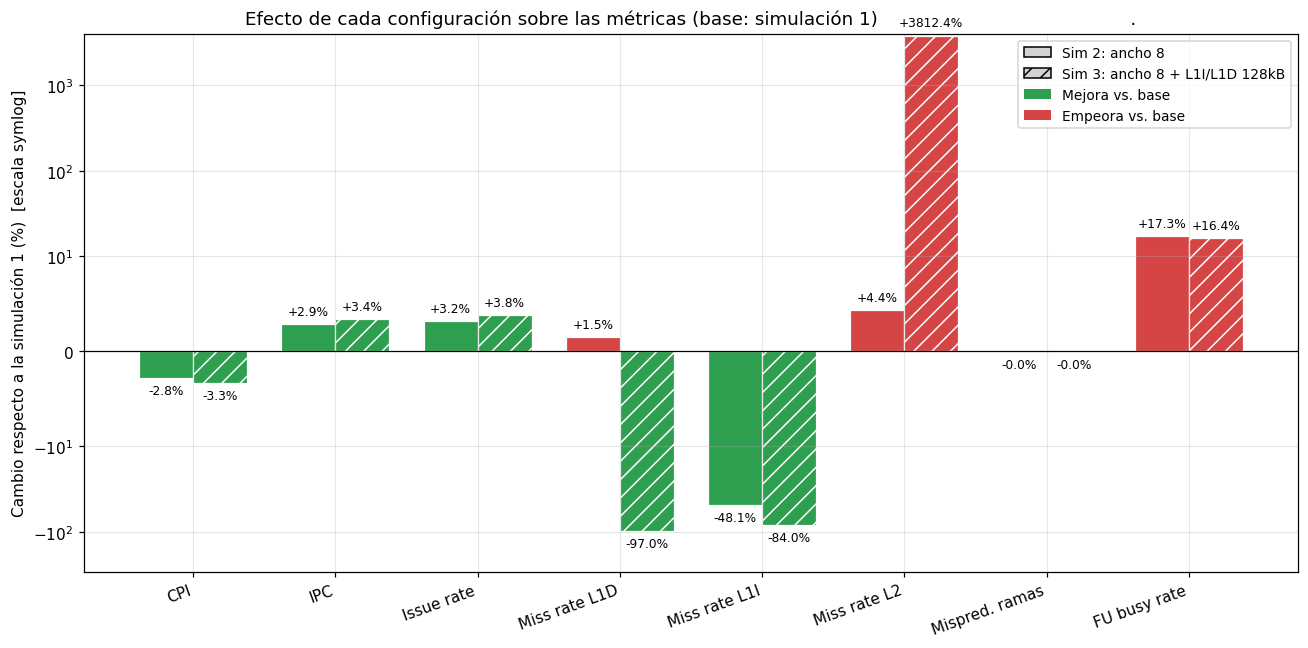

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# columna de e1 -> (etiqueta, ¿menor es mejor?)
METRICAS = {
    "cpi":          ("CPI",              True),
    "ipc":          ("IPC",              False),
    "issueRate":    ("Issue rate",       False),
    "dcache_miss":  ("Miss rate L1D",    True),
    "icache_miss":  ("Miss rate L1I",    True),
    "l2_miss":      ("Miss rate L2",     True),
    "mispred (%)":  ("Mispred. ramas",   True),
    "fuBusyRate":   ("FU busy rate",     True),  
}

base = e1.iloc[0]
cambio = {}  # % respecto a la simulación 1
for sim_idx, sim_name in [(1, "Sim 2: ancho 8"), (2, "Sim 3: ancho 8 + L1I/L1D 128kB")]:
    cambio[sim_name] = [(e1.iloc[sim_idx][c] / base[c] - 1) * 100 for c in METRICAS]

VERDE, ROJO, GRIS = "#2e9e4f", "#d64545", "#999999"
def color(pct, menor_mejor):
    if abs(pct) < 1e-9:
        return GRIS
    mejora = (pct < 0) if menor_mejor else (pct > 0)
    return VERDE if mejora else ROJO

x = np.arange(len(METRICAS))
w = 0.38
fig, ax = plt.subplots(figsize=(12, 6))

for k, (sim_name, vals) in enumerate(cambio.items()):
    hatch = "" if k == 0 else "//"          # sim 2 liso, sim 3 rayado
    offs = (k - 0.5) * w
    for i, ((col, (lab, menor_mejor)), v) in enumerate(zip(METRICAS.items(), vals)):
        ax.bar(x[i] + offs, v, w, color=color(v, menor_mejor), hatch=hatch,
               edgecolor="white", linewidth=0.8)
        ax.annotate(f"{v:+.1f}%", (x[i] + offs, v),
                    xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_yscale("symlog", linthresh=10)       # el miss rate de L2 en la sim 3 se dispara y aplastaría el resto
ax.set_xticks(x)
ax.set_xticklabels([v[0] for v in METRICAS.values()], rotation=20, ha="right")
ax.set_ylabel("Cambio respecto a la simulación 1 (%)  [escala symlog]")
ax.set_title("Efecto de cada configuración sobre las métricas (base: simulación 1)                                           .")
ax.grid(axis="y", alpha=0.3)

ax.legend(handles=[
    Patch(facecolor="lightgray", edgecolor="black", label="Sim 2: ancho 8"),
    Patch(facecolor="lightgray", edgecolor="black", hatch="//", label="Sim 3: ancho 8 + L1I/L1D 128kB"),
    Patch(facecolor=VERDE, label="Mejora vs. base"),
    Patch(facecolor=ROJO,  label="Empeora vs. base"),
], loc="best", fontsize=9)

plt.tight_layout()
plt.show()


**Resultados de las 3 simulaciones**
- **Ancho 4 → 8 (sim 2):** el CPI baja un 2.8 %. El IPC de la configuración base (≈1.10) está muy por debajo del ancho 4, por lo que el ancho no es el cuello de botella: ensancharlo apenas ayuda.
- **L1 de 128 kB (sim 3):** el fallo de L1D cae del 1.5 % al 0.04 %, pero el CPI apenas mejora un 0.5 % adicional. La tasa de fallo de L2 sube al 36 % solo porque L2 recibe muchos menos accesos totales.
- **Conclusión del Exp. 1:** Dado que multiplicar la caché y el ancho solo logra mejorar el CPI en un ~3.3% global, es correcto deducir que la causa del límite de rendimiento no está ni en el ancho de búsqueda/decodificación ni en la capacidad de las cachés L1, apuntando a otros recursos, como el número de instrucciones aritmético-lógicas de enteros o la cola de instrucciones.

## 3. Experimento 2: Definición y exploración del DSE (fuerza bruta)
### 3.1 Parámetros modificados
| Parámetro | Valores | Valor por defecto |
|---|---|---|
| `l1d_size` (tamaño L1 de datos) | 16 kB, 32 kB, 64 kB, 128 kB | 64 kB |
| `l2_size` (tamaño L2) | 128 kB, 256 kB, 512 kB, 1 MB | 256 kB |
| `num_fu_intALU` (ALUs enteras) | 1, 2, 3, 4 | 2 |
| `iq_entries` (cola de instrucciones) | 16, 32, 48, 64 | 16 |
| `rob_entries` (ROB) | 64, 128, 192, 256 | 128 |

El espacio completo tiene 4⁵ = **1024 combinaciones**, todas simuladas. El script `dse_exp2.py` las recorre en orden aleatorio (semilla fija), lanza 5 simulaciones en paralelo y es reanudable.

In [ ]:
%%writefile scripts/dse_exp2.py
#!/usr/bin/env python3
"""
Experimento 2: DSE de Cortex A76 en gem5 (sin McPAT).

Espacio: 4^5 = 1024 combinaciones. Se recorren en orden aleatorio (semilla fija),
5 simulaciones en paralelo, hasta agotar el presupuesto de tiempo.
Reanudable: las simulaciones ya terminadas (sims/<id>/result.json) se saltan.

Ejecutar desde la raiz de gem5:
    python3 dse_exp2.py --workers 5 --budget-hours 8.5
"""

import argparse
import csv
import itertools
import json
import os
import random
import shlex
import shutil
import subprocess
import sys
import time
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED

ROOT = os.getcwd()
GEM5_BIN = os.path.join(ROOT, "build/ARM/gem5.fast")
GEM5_CFG = os.path.join(ROOT, "scripts/CortexA76_scripts_gem5/CortexA76.py")
WORKLOAD = os.path.join(ROOT, "workloads/mp3_dec/mp3_dec")
WORKLOAD_IN = os.path.join(ROOT, "workloads/mp3_dec/mp3dec_testfile.mp3")
WORKLOAD_ARGS = "-w mp3dec_outfile.wav " + WORKLOAD_IN  # el wav sale en el dir de cada sim

SIMS_DIR = os.path.join(ROOT, "sims")
CSV_PATH = os.path.join(ROOT, "results_exp2.csv")

SPACE = {
    "l1d_size": ["16kB", "32kB", "64kB", "128kB"],
    "l2_size": ["128kB", "256kB", "512kB", "1MB"],
    "num_fu_intALU": [1, 2, 3, 4],
    "iq_entries": [16, 32, 48, 64],
    "rob_entries": [64, 128, 192, 256],
}
PARAMS = list(SPACE)
DEFAULT = {"l1d_size": "64kB", "l2_size": "256kB", "num_fu_intALU": 2,
           "iq_entries": 16, "rob_entries": 128}

STATS = ["simSeconds", "hostSeconds", "system.cpu.cpi", "system.cpu.ipc",
         "system.cpu.dcache.overallMissRate::total",
         "system.cpu.icache.overallMissRate::total",
         "system.cpu.l2cache.overallMissRate::total",
         "system.cpu.l3cache.overallMissRate::total"]


def cfg_id(cfg):
    return "_".join(f"{k}-{cfg[k]}" for k in PARAMS)


def read_stats(path):
    out = {n: None for n in STATS}
    with open(path) as f:
        for line in f:
            p = line.split()
            if len(p) >= 2 and p[0] in out and out[p[0]] is None:
                try:
                    out[p[0]] = float(p[1])
                except ValueError:
                    pass
    return out


def simulate(cfg):
    sid = cfg_id(cfg)
    simdir = os.path.join(SIMS_DIR, sid)
    result_path = os.path.join(simdir, "result.json")
    if os.path.exists(result_path):
        with open(result_path) as f:
            return json.load(f)

    if os.path.isdir(simdir):
        shutil.rmtree(simdir)
    os.makedirs(simdir)

    cmd = [GEM5_BIN, f"--outdir={simdir}", GEM5_CFG, "-d", simdir,
           "-c", WORKLOAD, "-o", WORKLOAD_ARGS] + [f"--{k}={cfg[k]}" for k in PARAMS]
    t0 = time.time()
    with open(os.path.join(simdir, "simout.txt"), "w") as out:
        out.write("CMD: " + " ".join(shlex.quote(c) for c in cmd) + "\n\n")
        out.flush()
        rc = subprocess.run(cmd, stdout=out, stderr=subprocess.STDOUT).returncode
    wall = time.time() - t0

    stats = os.path.join(simdir, "stats.txt")
    if rc != 0 or not os.path.exists(stats):
        print(f"[ERROR] {sid} (rc={rc})", flush=True)
        return {"id": sid, **cfg, "ok": False}

    s = read_stats(stats)
    res = {"id": sid, **cfg, "ok": True,
           "simSeconds": s["simSeconds"], "hostSeconds": s["hostSeconds"],
           "cpi": s["system.cpu.cpi"], "ipc": s["system.cpu.ipc"],
           "dcache_miss": s["system.cpu.dcache.overallMissRate::total"],
           "icache_miss": s["system.cpu.icache.overallMissRate::total"],
           "l2_miss": s["system.cpu.l2cache.overallMissRate::total"],
           "l3_miss": s["system.cpu.l3cache.overallMissRate::total"],
           "wall_s": wall}
    with open(result_path, "w") as f:
        json.dump(res, f)
    for fn in os.listdir(simdir):  # liberar disco
        if fn.endswith(".wav"):
            os.remove(os.path.join(simdir, fn))
    print(f"[OK] {sid}  CPI={res['cpi']}  ({wall/60:.1f} min)", flush=True)
    return res


def save_csv(done):
    if not done:
        return
    rows = list(done.values())
    with open(CSV_PATH, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--workers", type=int, default=5)
    ap.add_argument("--budget-hours", type=float, default=8.5)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--limit", type=int, default=None,
                    help="maximo de simulaciones (util para pruebas, ej. --limit 1)")
    args = ap.parse_args()

    for p in (GEM5_BIN, GEM5_CFG, WORKLOAD, WORKLOAD_IN):
        if not os.path.exists(p):
            sys.exit(f"No se encontro '{p}'. Ejecuta desde la carpeta de gem5.")
    os.makedirs(SIMS_DIR, exist_ok=True)

    # Todo el espacio, en orden aleatorio reproducible; la config por defecto va primero
    allc = [dict(zip(PARAMS, v)) for v in itertools.product(*SPACE.values())]
    random.Random(args.seed).shuffle(allc)
    allc = [DEFAULT] + [c for c in allc if cfg_id(c) != cfg_id(DEFAULT)]
    if args.limit:
        allc = allc[: args.limit]

    # Cargar lo ya hecho
    done = {}
    for c in allc:
        p = os.path.join(SIMS_DIR, cfg_id(c), "result.json")
        if os.path.exists(p):
            with open(p) as f:
                r = json.load(f)
            if r.get("ok"):
                done[r["id"]] = r
    pending_cfgs = [c for c in allc if cfg_id(c) not in done]
    print(f"Espacio: {len(allc)} configs | ya hechas: {len(done)} | por hacer: {len(pending_cfgs)}")

    deadline = time.time() + args.budget_hours * 3600
    it = iter(pending_cfgs)
    t_start = time.time()

    with ProcessPoolExecutor(max_workers=args.workers) as ex:
        running = set()

        def submit_next():
            if time.time() >= deadline:
                return False
            try:
                running.add(ex.submit(simulate, next(it)))
                return True
            except StopIteration:
                return False

        for _ in range(args.workers):
            submit_next()
        while running:
            finished, _ = wait(running, return_when=FIRST_COMPLETED)
            for fut in finished:
                running.discard(fut)
                r = fut.result()
                if r.get("ok"):
                    done[r["id"]] = r
                    save_csv(done)
                submit_next()

    print(f"\nTerminado: {len(done)} simulaciones en {(time.time()-t_start)/3600:.2f} h")
    print(f"CSV: {CSV_PATH}")


if __name__ == "__main__":
    main()

### 3.2 Comando de ejecución:
Para la simulación se varió el parámetro --budget-hours para realizar tandas en diferentes momentos.

In [ ]:
run_script("dse_exp2.py", "--workers", "5", "--budget-hours", "8.5")

In [14]:
exp2 = pd.read_csv(RESULTS_DIR / "exp2" / "results_exp2.csv")
exp2 = exp2[exp2.ok]
print(len(exp2), "simulaciones válidas de 1024")
P5 = ["l1d_size", "l2_size", "num_fu_intALU", "iq_entries", "rob_entries"]
DEF = {"l1d_size":"64kB","l2_size":"256kB","num_fu_intALU":2,"iq_entries":16,"rob_entries":128}
dflt = exp2[(exp2[P5] == pd.Series(DEF)).all(axis=1)].iloc[0]
print(f"CPI configuración por defecto: {dflt.cpi:.4f}  |  mejor CPI de la fuerza bruta: {exp2.cpi.min():.4f} "
      f"({(exp2.cpi.min()/dflt.cpi-1)*100:.1f} %)")
exp2.sort_values("cpi")[["id","cpi","ipc","simSeconds","dcache_miss","l2_miss"]].head(10).round(4)

1024 simulaciones válidas de 1024
CPI configuración por defecto: 0.9061  |  mejor CPI de la fuerza bruta: 0.7498 (-17.2 %)


,id,cpi,ipc,simSeconds,dcache_miss,l2_miss
384,l1d_size-128kB_l2_size-512kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2310
528,l1d_size-128kB_l2_size-512kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2309
214,l1d_size-128kB_l2_size-1MB_num_fu_intALU-3_iq_...,0.7498,1.3337,0.0823,0.0004,0.2308
896,l1d_size-128kB_l2_size-1MB_num_fu_intALU-3_iq_...,0.7498,1.3337,0.0823,0.0004,0.2309
688,l1d_size-128kB_l2_size-1MB_num_fu_intALU-3_iq_...,0.7498,1.3337,0.0823,0.0004,0.2310
166,l1d_size-128kB_l2_size-512kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2311
358,l1d_size-128kB_l2_size-512kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2305
937,l1d_size-128kB_l2_size-1MB_num_fu_intALU-3_iq_...,0.7498,1.3337,0.0823,0.0004,0.2304
779,l1d_size-128kB_l2_size-256kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2345
284,l1d_size-128kB_l2_size-512kB_num_fu_intALU-3_i...,0.7498,1.3337,0.0823,0.0004,0.2316


### 3.3 Rendimiento frente a recursos

Cada punto es el CPI medio de las 256 simulaciones que comparten ese valor del parámetro. 

La banda va del mínimo al máximo. 

Línea discontinua: valor por defecto.

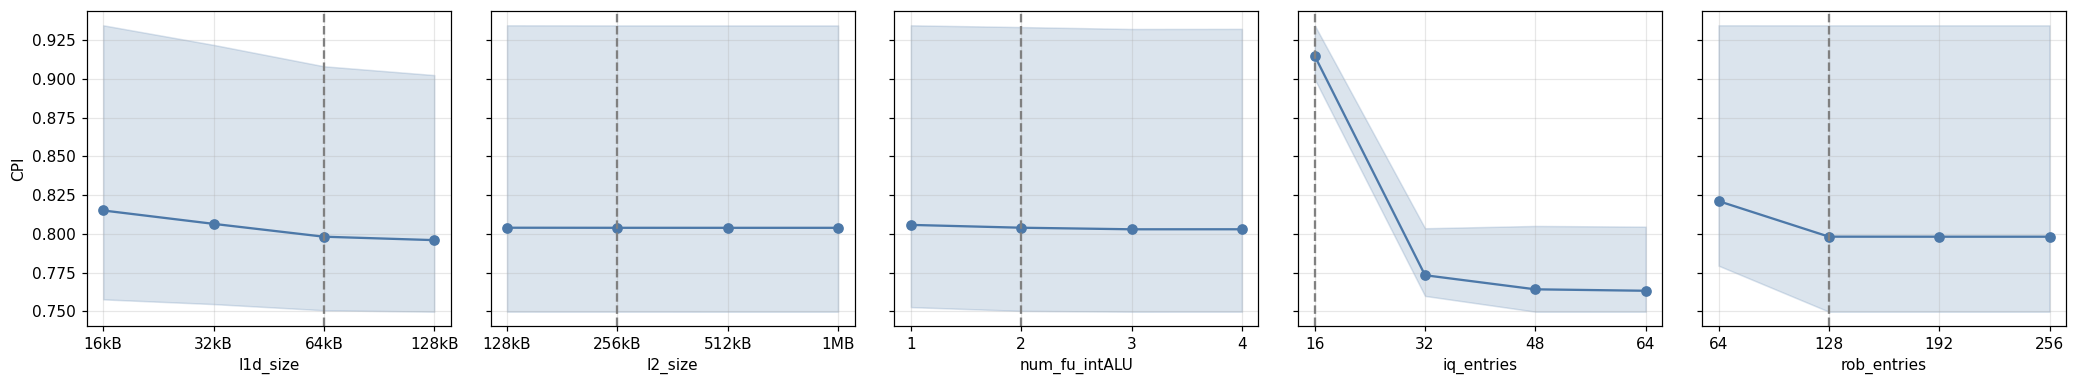

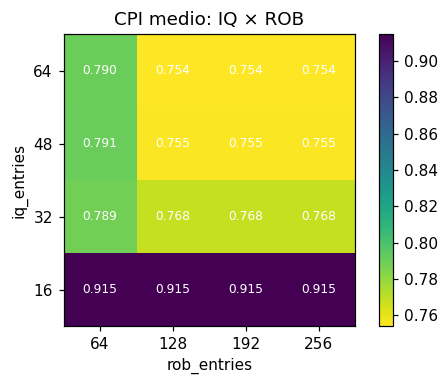

In [15]:
fig, axs = plt.subplots(1, 5, figsize=(19, 3.6), sharey=True)
for ax, p in zip(axs, P5):
    vals = sorted(exp2[p].unique(), key=kb if p.endswith("size") else float)
    g = exp2.groupby(p).cpi.agg(["mean","min","max"]).loc[vals]
    x = range(len(vals))
    ax.plot(x, g["mean"], "o-", color="#4c78a8"); ax.fill_between(x, g["min"], g["max"], alpha=0.2, color="#4c78a8")
    ax.set_xticks(list(x)); ax.set_xticklabels([str(v) for v in vals]); ax.set_xlabel(p)
    ax.axvline(vals.index(DEF[p]), ls="--", c="gray")
axs[0].set_ylabel("CPI")
plt.tight_layout(); plt.show()

piv = exp2.pivot_table(index="iq_entries", columns="rob_entries", values="cpi", aggfunc="mean")
fig, ax = plt.subplots(figsize=(4.8, 3.6))
im = ax.imshow(piv.values, cmap="viridis_r", origin="lower")
ax.set_xticks(range(4)); ax.set_xticklabels(piv.columns); ax.set_yticks(range(4)); ax.set_yticklabels(piv.index)
ax.set_xlabel("rob_entries"); ax.set_ylabel("iq_entries"); ax.set_title("CPI medio: IQ × ROB")
for i in range(4):
    for j in range(4): ax.text(j, i, f"{piv.values[i,j]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax.grid(False); plt.colorbar(im); plt.tight_layout(); plt.show()

**Análisis**

- **`iq_entries` :** Aumentar la Cola de Instrucciones o estaciones de reserva fue lo que tuvo mas impacto, pasar de 16 a 32 entradas reduce el CPI medio de 0.915 a 0.773 (−15.5 %); de 32 a 64 solo mejora otro 1.3 %. La cola por defecto (16) causa un cuello de botella, lo que explica por qué el ancho y las cachés del Exp. 1 casi no ayudaban.

- **`rob_entries`:**  El número de ranuras disponibles en el Reorder Buffer mejora el CPI solamente al pasar de 64 a 128, más allá de 128 no hay ninguna ganancia, 192 y 256 dan el mismo CPI medio.

- **`l1d_size`:** El tamaño de la memoria caché L1 de datos tuvo un efecto moderado y con rendimientos decrecientes (0.815 → 0.806 → 0.798 → 0.796).

- **`l2_size`:** El tamaño de la memoria caché L2 tuvo un efecto prácticamente nulo (0.8040 → 0.8039): el conjunto de trabajo ya cabe en L2/L1.

- **`num_fu_intALU`:** Las unidades funcionales de tipo ALU tuvieron un efecto muy pequeño (0.806 con 1 ALU frente a 0.803 con 3 o 4).

- El rango global de CPI va de 0.7498 a 0.9345.

## 4. Experimento 3 — Estrategia inteligente: algoritmo evolutivo NSGA‑II
### 4.1 Diseño

Cuando se optimizan dos objetivos a la vez (aquí **CPI** y **Energy**, ambos a minimizar), normalmente no existe una única configuración que sea la mejor en los dos: mejorar el rendimiento suele costar energía, y viceversa. Para comparar configuraciones se usa el concepto de **dominancia de Pareto**:

- Una configuración **A domina** a otra **B** si A es al menos tan buena como B en ambos objetivos y estrictamente mejor en al menos uno (por ejemplo, menor CPI y menor o igual Energy).
- Una configuración es **no dominada** si ninguna otra la domina.
- El conjunto de todas las configuraciones no dominadas es el **frente de Pareto**. Representa los mejores compromisos posibles entre rendimiento y energía: desde cualquier punto del frente, mejorar un objetivo obliga a empeorar el otro.

- **Genoma de 14 genes ordinales** (≈ 1.1×10⁸ posibles combinaciones, frente a las 1024 de la fuerza bruta):

| Gen | Significado | Valores |
|---|---|---|
| `l1i_size` | Tamaño de la caché L1 de instrucciones | 16, 32, 64, 128 kB |
| `l1d_size` | Tamaño de la caché L1 de datos | 16, 32, 64, 128 kB |
| `l2_size` | Tamaño de la caché L2 unificada (instrucciones y datos) | 128, 256, 512 kB, 1 MB |
| `l1i_assoc` | Asociatividad (número de vías) de la L1 de instrucciones: más vías reducen los fallos por conflicto | 2, 4, 8 |
| `l1d_assoc` | Asociatividad de la L1 de datos | 2, 4, 8 |
| `l2_assoc` | Asociatividad de la L2 | 4, 8, 16 |
| `front_width` | Ancho del *front-end*: instrucciones por ciclo que se buscan (*fetch*), decodifican (*decode*) y renombran (*rename*); los tres valores se mantienen iguales | 2, 4, 6, 8 |
| `issue_width` | Ancho de despacho (*dispatch*) y emisión (*issue*): instrucciones por ciclo que entran a la cola de instrucciones y salen hacia las unidades funcionales | 2, 4, 6, 8 |
| `commit_width` | Ancho de retiro: instrucciones por ciclo que se confirman (*commit*) y escriben su resultado (*write-back*) | 2, 4, 6, 8 |
| `iq_entries` | Entradas de la cola de instrucciones: instrucciones esperando operandos o unidad funcional para ejecutarse fuera de orden | 16, 32, 48, 64 |
| `rob_entries` | Entradas del *Reorder Buffer*: instrucciones que esperan retirarse en orden; define cuánto puede adelantarse la ejecución fuera de orden | 64, 128, 192, 256 |
| `lq_entries` | Entradas de la cola de cargas: lecturas de memoria | 32, 48, 68, 96 |
| `sq_entries` | Entradas de la cola de almacenamientos: escrituras a memoria | 32, 48, 72, 96 |
| `btb_entries` | Entradas del *Branch Target Buffer*: guarda las direcciones destino de los saltos para predecirlos sin esperar | 1024, 2048, 4096, 8192 |


#### 4.1.1 Operadores evolutivos

Cada individuo es un genoma de 14 genes ordinales cada gen toma un valor de una lista ordenada. Los dos objetivos, a minimizar, son CPI y Energy (= Power × CPI). Los parámetros son μ = 24 (tamaño de la población) y λ = 24 (hijos por generación), con semilla 42.

- **Selección de padres: torneo binario.** Se eligen al azar dos individuos de la población y gana el de menor *rango de no dominancia* (frente de Pareto al que pertenece; el frente 0 es el mejor). Si ambos tienen el mismo rango, gana el que tenga mayor *crowding distance* (distancia de aglomeración), lo que favorece a los individuos situados en zonas poco pobladas del frente y mantiene la diversidad. Se repite el proceso para obtener los dos padres de cada hijo.
- **Cruce uniforme (p<sub>c</sub> = 0.9).** Con probabilidad 0.9 se combinan los padres: cada uno de los 14 genes se hereda del padre A o del B con probabilidad 0.5, de forma independiente. Con probabilidad 0.1 no hay cruce y el hijo es una copia del primer padre (antes de la mutación).
- **Mutación por gen (p<sub>m</sub> = 0.15).** Cada gen muta de forma independiente con probabilidad 0.15 (en promedio 14 × 0.15 = 2.1 genes por hijo). Cuando un gen muta, el 60 % de las veces se desplaza a un valor *vecino* en su lista ordenada (índice ±1, acotado en los extremos), lo que produce cambios pequeños y favorece la explotación local; el 40 % restante se reasigna a un valor aleatorio de la lista, lo que permite saltos grandes y favorece la exploración.
- **Evitar duplicados.** Como cada evaluación cuesta ~13 minutos, al generar un hijo se reintenta (hasta 40 veces) si su genoma ya fue evaluado en generaciones anteriores o ya está en el lote actual.
- **Reemplazo (μ + λ).** Los 24 padres y los 24 hijos se juntan en un conjunto de 48 individuos, que se ordena en frentes mediante *fast non-dominated sorting* (F₀, F₁, F₂, …). La nueva población se llena frente a frente; el último frente que no cabe completo se trunca ordenando por *crowding distance* decreciente. Como los padres compiten con sus hijos, los mejores individuos nunca se pierden.
- **Crowding distance.** Dentro de un frente, para cada objetivo se ordenan los individuos y se asigna distancia infinita a los extremos; a los demás se les suma la diferencia normalizada entre sus dos vecinos. Valores altos indican zonas poco densas.

#### 4.1.2 Tubería de evaluación, caché y reanudación

Cada evaluación de un individuo ejecuta la cadena completa dentro de un mismo proceso trabajador: **gem5** (simulación del Cortex-A76 con `mp3_dec`) → **conversor** `gem5toMcPAT_cortexA76.py` (combina `stats.txt`, `config.json` y la plantilla `ARM_A76_2.1GHz.xml` en un `config.xml`) → **McPAT** (se extraen `Total Leakage` y `Runtime Dynamic` del bloque *Processor*). Con ellos se calculan Power, Energy y EDP.

Para tolerar un cómputo de decenas de horas, el proceso es reanudable:
- Cada genoma recibe un identificador determinista (hash MD5 de sus 14 valores) y su resultado se guarda en `evo/sims/<id>/result.json`. Si un individuo ya fue evaluado, se reutiliza y no se vuelve a simular.
- El estado de cada generación se guarda en `generations.json` y los hijos de cada generación se generan de forma determinista a partir de (semilla, generación, población), de modo que al reanudar se regeneran los mismos hijos.
- La ejecución se hizo por tandas (`--budget-hours 8.5`, 6 workers en paralelo). El planificador no lanza una evaluación si, según la mediana de los últimos tiempos, no terminaría dentro del presupuesto restante; lo ya evaluado queda en caché para la tanda siguiente.

#### 4.1.3 Exclusión de `num_fu_intALU` del genoma

El número de ALU enteras (`--num_fu_intALU`) sí es un parámetro efectivo en gem5: modifica el `count` de la unidad funcional y, por tanto, el rendimiento (en la fuerza bruta, el CPI medio varía de 0.806 con 1 ALU a 0.803 con 3 o 4). Sin embargo, el modelo de potencia no lo recoge. En el conversor `gem5toMcPAT_cortexA76.py`, los parámetros `ALU_per_core`, `MUL_per_core` y `FPU_per_core` están mapeados como `"default"`, es decir, no se leen de la configuración de gem5 y McPAT conserva los valores fijos de la plantilla XML (3 ALU, 1 MUL, 2 FPU).

#### 4.1.4 Población inicial y sembrado

El script permite sembrar la generación 0 con información de la fuerza bruta mediante `--seed-csv`. Se añaden a la población inicial tres individuos: los mejores de la fuerza bruta en CPI, Energy y EDP (completando con los valores por defecto los genes que la fuerza bruta no exploró), además de la configuración por defecto y individuos aleatorios hasta completar μ = 24. Si el archivo no se encuentra en la ruta indicada, el script no siembra y continúa sin avisar.

En la ejecución real no se aplicó el sembrado para comparar los resultados de ambos metodos de forma independiente.

In [ ]:
%%writefile scripts/evo_nsga2.py
#!/usr/bin/env python3
"""
Experimento 3: exploracion evolutiva (NSGA-II) del DSE de Cortex A76.

Objetivos (ambos a minimizar):
    1) CPI
    2) Energy = Power * CPI      (Power = Leakage + Runtime Dynamic de McPAT)
   EDP = Energy * CPI se calcula por individuo; su optimo siempre cae sobre el
   frente de Pareto (CPI, Energy), asi que un solo experimento da los tres
   mejores pedidos (rendimiento, energia y EDP).

Cada evaluacion = gem5 + conversor gem5->McPAT + McPAT, todo dentro del mismo
worker (misma tuberia que dse_exp2.py + edp_exp4.py). El XML plantilla NO se
modifica.

Genoma (14 genes). Parametros que McPAT no mapea (num_fu_*, predictor de
ramas, ...) se dejan en su valor por defecto. Anchos agrupados:
    front_width  -> fetch = decode = rename
    issue_width  -> issue = dispatch
    commit_width -> commit = wb
Latencias de cache ligadas al tamano (ver tablas LAT_*).

Reanudable: cada evaluacion se guarda en evo/sims/<id>/result.json y el estado
de las generaciones en evo/generations.json. Se puede ejecutar por tandas con
distinto --budget-hours; la cache evita repetir simulaciones.

Ejecutar desde la raiz de gem5:
    python3 evo_nsga2.py --smoke                      # prueba: solo config por defecto
    python3 evo_nsga2.py --workers 6 --budget-hours 8.5
    python3 evo_nsga2.py --workers 6 --budget-hours 6  # continuar otra tanda
"""

import argparse
import csv
import hashlib
import json
import math
import os
import random
import re
import shlex
import shutil
import statistics
import subprocess
import sys
import time
from collections import OrderedDict
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED

ROOT = os.getcwd()
GEM5_BIN = os.path.join(ROOT, "build/ARM/gem5.fast")
GEM5_CFG = os.path.join(ROOT, "scripts/CortexA76_scripts_gem5/CortexA76.py")
WORKLOAD = os.path.join(ROOT, "workloads/mp3_dec/mp3_dec")
WORKLOAD_IN = os.path.join(ROOT, "workloads/mp3_dec/mp3dec_testfile.mp3")
WORKLOAD_ARGS = "-w mp3dec_outfile.wav " + WORKLOAD_IN

MCPAT_BIN = os.path.join(ROOT, "mcpat/mcpat")
CONVERTER = os.path.join(ROOT, "scripts/McPAT/gem5toMcPAT_cortexA76.py")
TEMPLATE = os.path.join(ROOT, "scripts/McPAT/ARM_A76_2.1GHz.xml")

OUT_DIR = os.path.join(ROOT, "evo")
SIMS_DIR = os.path.join(OUT_DIR, "sims")
GEN_PATH = os.path.join(OUT_DIR, "generations.json")
EVALS_CSV = os.path.join(OUT_DIR, "evals_all.csv")
PARETO_CSV = os.path.join(OUT_DIR, "pareto.csv")
HISTORY_CSV = os.path.join(OUT_DIR, "history.csv")
SUMMARY = os.path.join(OUT_DIR, "summary.txt")

# ----------------------------------------------------------------------
# Espacio de busqueda (14 genes) -- todos ordinales
# ----------------------------------------------------------------------
SPACE = OrderedDict([
    ("l1i_size", ["16kB", "32kB", "64kB", "128kB"]),
    ("l1d_size", ["16kB", "32kB", "64kB", "128kB"]),
    ("l2_size", ["128kB", "256kB", "512kB", "1MB"]),
    ("l1i_assoc", [2, 4, 8]),
    ("l1d_assoc", [2, 4, 8]),
    ("l2_assoc", [4, 8, 16]),
    ("front_width", [2, 4, 6, 8]),
    ("issue_width", [2, 4, 6, 8]),
    ("commit_width", [2, 4, 6, 8]),
    ("iq_entries", [16, 32, 48, 64]),
    ("rob_entries", [64, 128, 192, 256]),
    ("lq_entries", [32, 48, 68, 96]),
    ("sq_entries", [32, 48, 72, 96]),
    ("btb_entries", [1024, 2048, 4096, 8192]),
])
GENES = list(SPACE)

# Configuracion por defecto del Cortex A76 del laboratorio
DEFAULT = {
    "l1i_size": "64kB", "l1d_size": "64kB", "l2_size": "256kB",
    "l1i_assoc": 4, "l1d_assoc": 4, "l2_assoc": 8,
    "front_width": 4, "issue_width": 8, "commit_width": 4,
    "iq_entries": 16, "rob_entries": 128, "lq_entries": 68,
    "sq_entries": 72, "btb_entries": 4096,
}

# Latencia (ciclos) ligada al tamano: caches mas grandes -> mas lentas
LAT_L1I = {"16kB": 2, "32kB": 2, "64kB": 2, "128kB": 3}
LAT_L1D = {"16kB": 3, "32kB": 3, "64kB": 4, "128kB": 5}
LAT_L2 = {"128kB": 8, "256kB": 9, "512kB": 10, "1MB": 12}

RE_LEAK = re.compile(r"^\s*Total Leakage\s*=\s*([-+0-9.eE]+)\s*W")
RE_DYN = re.compile(r"^\s*Runtime Dynamic\s*=\s*([-+0-9.eE]+)\s*W")

STATS = ["simSeconds", "hostSeconds", "simInsts", "system.cpu.cpi", "system.cpu.ipc",
         "system.cpu.dcache.overallMissRate::total",
         "system.cpu.icache.overallMissRate::total",
         "system.cpu.l2cache.overallMissRate::total"]


# ----------------------------------------------------------------------
# Utilidades de genoma
# ----------------------------------------------------------------------
def genome_id(g):
    key = "|".join(f"{k}={g[k]}" for k in GENES)
    return "g_" + hashlib.md5(key.encode()).hexdigest()[:12]


def gem5_options(g):
    o = [
        f"--l1i_size={g['l1i_size']}", f"--l1i_assoc={g['l1i_assoc']}", f"--l1i_lat={LAT_L1I[g['l1i_size']]}",
        f"--l1d_size={g['l1d_size']}", f"--l1d_assoc={g['l1d_assoc']}", f"--l1d_lat={LAT_L1D[g['l1d_size']]}",
        f"--l2_size={g['l2_size']}", f"--l2_assoc={g['l2_assoc']}", f"--l2_lat={LAT_L2[g['l2_size']]}",
        f"--fetch_width={g['front_width']}", f"--decode_width={g['front_width']}",
        f"--rename_width={g['front_width']}",
        f"--issue_width={g['issue_width']}", f"--dispatch_width={g['issue_width']}",
        f"--commit_width={g['commit_width']}", f"--wb_width={g['commit_width']}",
        f"--iq_entries={g['iq_entries']}", f"--rob_entries={g['rob_entries']}",
        f"--lq_entries={g['lq_entries']}", f"--sq_entries={g['sq_entries']}",
        f"--btb_entries={g['btb_entries']}",
    ]
    return o


def write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f)
    os.replace(tmp, path)


# ----------------------------------------------------------------------
# Evaluacion de un individuo (se ejecuta en un worker)
# ----------------------------------------------------------------------
def read_stats(path):
    out = {n: None for n in STATS}
    with open(path) as f:
        for line in f:
            p = line.split()
            if len(p) >= 2 and p[0] in out and out[p[0]] is None:
                try:
                    out[p[0]] = float(p[1])
                except ValueError:
                    pass
    return out


def parse_mcpat(path):
    """Primera aparicion de Total Leakage / Runtime Dynamic tras 'Processor:'."""
    leak = dyn = None
    in_proc = False
    with open(path) as f:
        for line in f:
            if line.strip() == "Processor:":
                in_proc = True
                continue
            if not in_proc:
                continue
            if leak is None:
                m = RE_LEAK.match(line)
                if m:
                    leak = float(m.group(1))
            if dyn is None:
                m = RE_DYN.match(line)
                if m:
                    dyn = float(m.group(1))
            if leak is not None and dyn is not None:
                break
    return leak, dyn


def simulate(genome, gen):
    gid = genome_id(genome)
    simdir = os.path.join(SIMS_DIR, gid)
    rpath = os.path.join(simdir, "result.json")
    if os.path.exists(rpath):
        with open(rpath) as f:
            return json.load(f)
    if os.path.isdir(simdir):
        shutil.rmtree(simdir)
    os.makedirs(simdir)

    base = {"id": gid, **{k: genome[k] for k in GENES}, "gen": gen}
    t_all = time.time()

    def fail(msg):
        print(f"[ERROR] {gid}: {msg}", flush=True)
        r = {**base, "ok": False, "error": msg}
        write_json(rpath, r)
        return r

    # 1) gem5
    cmd = [GEM5_BIN, f"--outdir={simdir}", GEM5_CFG, "-d", simdir,
           "-c", WORKLOAD, "-o", WORKLOAD_ARGS] + gem5_options(genome)
    t0 = time.time()
    with open(os.path.join(simdir, "simout.txt"), "w") as out:
        out.write("CMD: " + " ".join(shlex.quote(c) for c in cmd) + "\n\n")
        out.flush()
        rc = subprocess.run(cmd, stdout=out, stderr=subprocess.STDOUT).returncode
    t_gem5 = time.time() - t0
    stats = os.path.join(simdir, "stats.txt")
    cfgjson = os.path.join(simdir, "config.json")
    if rc != 0 or not os.path.exists(stats) or not os.path.exists(cfgjson):
        return fail(f"gem5 rc={rc}")
    s = read_stats(stats)
    cpi = s["system.cpu.cpi"]
    if cpi is None:
        return fail("sin CPI en stats.txt")
    for fn in os.listdir(simdir):          # liberar disco
        if fn.endswith(".wav"):
            os.remove(os.path.join(simdir, fn))

    # 2) conversor gem5 -> McPAT (escribe config.xml en cwd)
    t0 = time.time()
    conv = subprocess.run([sys.executable, CONVERTER, stats, cfgjson, TEMPLATE],
                          cwd=simdir, capture_output=True, text=True)
    t_conv = time.time() - t0
    xml = os.path.join(simdir, "config.xml")
    if conv.returncode != 0 or not os.path.exists(xml):
        return fail("conversor: " + conv.stderr[-300:])

    # 3) McPAT
    t0 = time.time()
    out_txt = os.path.join(simdir, "mcpat_out.txt")
    with open(out_txt, "w") as out:
        rc = subprocess.run([MCPAT_BIN, "-infile", xml, "-print_level", "1"],
                            cwd=simdir, stdout=out, stderr=subprocess.STDOUT).returncode
    t_mcpat = time.time() - t0
    leak, dyn = parse_mcpat(out_txt)
    if rc != 0 or leak is None or dyn is None:
        return fail(f"McPAT rc={rc} leak={leak} dyn={dyn}")

    power = leak + dyn
    energy = power * cpi          # formula de la guia
    edp = energy * cpi            # formula de la guia
    res = {
        **base, "ok": True,
        "cpi": cpi, "ipc": s["system.cpu.ipc"],
        "simSeconds": s["simSeconds"], "hostSeconds": s["hostSeconds"],
        "simInsts": s["simInsts"],
        "dcache_miss": s["system.cpu.dcache.overallMissRate::total"],
        "icache_miss": s["system.cpu.icache.overallMissRate::total"],
        "l2_miss": s["system.cpu.l2cache.overallMissRate::total"],
        "leakage_W": leak, "dynamic_W": dyn, "power_W": power,
        "energy": energy, "edp": edp,
        "energy_J": power * s["simSeconds"],
        "gem5_wall_s": t_gem5, "converter_seconds": t_conv,
        "mcpat_seconds": t_mcpat, "wall_total_s": time.time() - t_all,
        "finished_at": time.time(),
    }
    write_json(rpath, res)
    print(f"[OK] gen{gen} {gid} CPI={cpi:.4f} P={power:.3f}W EDP={edp:.4f} "
          f"({res['wall_total_s']/60:.1f} min)", flush=True)
    return res


# ----------------------------------------------------------------------
# NSGA-II
# ----------------------------------------------------------------------
def objective(r):
    return (r["cpi"], r["energy"])


def dominates(a, b):
    return all(x <= y for x, y in zip(a, b)) and any(x < y for x, y in zip(a, b))


def fast_nds(objs):
    n = len(objs)
    S = [[] for _ in range(n)]
    cnt = [0] * n
    fronts = [[]]
    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if dominates(objs[p], objs[q]):
                S[p].append(q)
            elif dominates(objs[q], objs[p]):
                cnt[p] += 1
        if cnt[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                cnt[q] -= 1
                if cnt[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    return fronts[:-1]


def crowding(front, objs):
    d = {i: 0.0 for i in front}
    for m in range(len(objs[0])):
        s = sorted(front, key=lambda i: objs[i][m])
        lo, hi = objs[s[0]][m], objs[s[-1]][m]
        d[s[0]] = d[s[-1]] = math.inf
        if hi > lo:
            for k in range(1, len(s) - 1):
                d[s[k]] += (objs[s[k + 1]][m] - objs[s[k - 1]][m]) / (hi - lo)
    return [d[i] for i in front]


def rank_and_crowd(objs):
    fronts = fast_nds(objs)
    rank = [0] * len(objs)
    crowd = [0.0] * len(objs)
    for r, f in enumerate(fronts):
        cd = crowding(f, objs)
        for i, c in zip(f, cd):
            rank[i] = r
            crowd[i] = c
    return rank, crowd


def nsga_select(ids, evals, mu):
    """Supervivientes (mu+lambda): por frente y, en el ultimo, por crowding."""
    objs = [objective(evals[i]) for i in ids]
    out = []
    for f in fast_nds(objs):
        if len(out) + len(f) <= mu:
            out += [ids[i] for i in f]
        else:
            cd = crowding(f, objs)
            order = sorted(range(len(f)), key=lambda k: -cd[k])
            out += [ids[f[k]] for k in order[: mu - len(out)]]
            break
    return out


def crossover(a, b, rng, pc=0.9):
    if rng.random() > pc:
        return dict(a)
    return {k: (a[k] if rng.random() < 0.5 else b[k]) for k in GENES}


def mutate(g, rng, pm):
    g = dict(g)
    for k in GENES:
        if rng.random() < pm:
            vals = SPACE[k]
            i = vals.index(g[k])
            if rng.random() < 0.6:       # paso a un valor vecino
                j = min(len(vals) - 1, max(0, i + rng.choice([-1, 1])))
            else:                        # salto aleatorio
                j = rng.randrange(len(vals))
            g[k] = vals[j]
    return g


def random_genome(rng):
    return {k: rng.choice(SPACE[k]) for k in GENES}


def make_offspring(pop_ids, evals, gen, lam, seen_ids, args):
    """Determinista para (seed, gen, poblacion): al reanudar regenera los mismos hijos."""
    rng = random.Random(f"{args.seed}-{gen}")
    objs = [objective(evals[i]) for i in pop_ids]
    rank, crowd = rank_and_crowd(objs)
    n = len(pop_ids)

    def tournament():
        if n == 1:
            return 0
        a, b = rng.sample(range(n), 2)
        if rank[a] != rank[b]:
            return a if rank[a] < rank[b] else b
        return a if crowd[a] >= crowd[b] else b

    genome_of = {i: {k: evals[i][k] for k in GENES} for i in pop_ids}
    children, batch_ids = [], set()
    for _ in range(lam):
        child = cid = None
        for _try in range(40):
            p1, p2 = pop_ids[tournament()], pop_ids[tournament()]
            child = mutate(crossover(genome_of[p1], genome_of[p2], rng), rng, args.mut_prob)
            cid = genome_id(child)
            if cid not in seen_ids and cid not in batch_ids:
                break
        if cid not in batch_ids:
            children.append(child)
            batch_ids.add(cid)
    return children


# ----------------------------------------------------------------------
# Poblacion inicial, E/S y reportes
# ----------------------------------------------------------------------
def brute_force_seeds(path):
    seeds = []
    if not path or not os.path.exists(path):
        return seeds
    with open(path, newline="") as f:
        rows = list(csv.DictReader(f))
    for key in ("cpi", "energy", "edp"):
        r = min(rows, key=lambda r: float(r[key]))
        g = dict(DEFAULT)
        for k in ("l1d_size", "l2_size", "iq_entries", "rob_entries"):
            v = int(r[k]) if k.endswith("entries") else r[k]
            if v in SPACE[k]:
                g[k] = v
        seeds.append(g)
    return seeds


def initial_population(mu, seeds, seed):
    rng = random.Random(f"{seed}-init")
    pop, ids = [], set()
    for g in [dict(DEFAULT)] + seeds:
        if genome_id(g) not in ids:
            pop.append(g)
            ids.add(genome_id(g))
    while len(pop) < mu:
        g = random_genome(rng)
        if genome_id(g) not in ids:
            pop.append(g)
            ids.add(genome_id(g))
    return pop[:mu] if len(pop) > mu else pop


def load_evals(retry_failed=False):
    evals = {}
    if not os.path.isdir(SIMS_DIR):
        return evals
    for d in os.listdir(SIMS_DIR):
        p = os.path.join(SIMS_DIR, d, "result.json")
        if os.path.exists(p):
            with open(p) as f:
                r = json.load(f)
            if not r.get("ok") and retry_failed:
                shutil.rmtree(os.path.join(SIMS_DIR, d))
                continue
            evals[r["id"]] = r
    return evals


def ok_rows(evals):
    return sorted([r for r in evals.values() if r.get("ok")], key=lambda r: r["finished_at"])


def write_csv(path, rows):
    if not rows:
        return
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)


def best_so_far(rows):
    if not rows:
        return {}
    return {"best_cpi": min(r["cpi"] for r in rows),
            "best_energy": min(r["energy"] for r in rows),
            "best_edp": min(r["edp"] for r in rows)}


def save_reports(evals, generations):
    rows = ok_rows(evals)
    if not rows:
        return
    write_csv(EVALS_CSV, rows)
    objs = [objective(r) for r in rows]
    write_csv(PARETO_CSV, sorted([rows[i] for i in fast_nds(objs)[0]], key=lambda r: r["cpi"]))
    hist = [{"gen": g["gen"], "n_evals": g["n_evals"], "pop_size": len(g["pop"]),
             **{k: g[k] for k in ("best_cpi", "best_energy", "best_edp")}} for g in generations]
    write_csv(HISTORY_CSV, hist)


def fmt(r):
    cfg = ", ".join(f"{k}={r[k]}" for k in GENES)
    return (f"{cfg}\n      CPI={r['cpi']:.4f}  Power={r['power_W']:.3f} W  "
            f"Energy={r['energy']:.4f}  EDP={r['edp']:.4f}")


def write_summary(evals, generations, bf_csv, wall_total):
    rows = ok_rows(evals)
    if not rows:
        return
    L = [f"Evaluaciones validas: {len(rows)} | generaciones completadas: {len(generations)}", ""]
    for title, key in [("Mejor RENDIMIENTO (CPI minimo)", "cpi"),
                       ("Mejor ENERGIA (Energy minima)", "energy"),
                       ("Mejor EDP (EDP minimo)", "edp")]:
        L.append(f"== Top 3 - {title} ==")
        for i, r in enumerate(sorted(rows, key=lambda r: r[key])[:3], 1):
            L.append(f"  {i}. {fmt(r)}")
        L.append("")
    d = evals.get(genome_id(DEFAULT))
    if d and d.get("ok"):
        L += ["Config por defecto A76: " + f"CPI={d['cpi']:.4f} Energy={d['energy']:.4f} EDP={d['edp']:.4f}", ""]
    if bf_csv and os.path.exists(bf_csv):
        with open(bf_csv, newline="") as f:
            bf = list(csv.DictReader(f))
        L.append("Mejor de la fuerza bruta (5 parametros, 1024 sims): "
                 f"CPI={min(float(r['cpi']) for r in bf):.4f} "
                 f"Energy={min(float(r['energy']) for r in bf):.4f} "
                 f"EDP={min(float(r['edp']) for r in bf):.4f}")
        L.append("")
    g5 = [r["hostSeconds"] for r in rows]
    gw = [r["gem5_wall_s"] for r in rows]
    tm = [r["mcpat_seconds"] for r in rows]
    tc = [r["converter_seconds"] for r in rows]
    L += ["== Velocidades ==",
          f"gem5 : {sum(g5)/len(g5):.1f} s/sim (hostSeconds) | pared {sum(gw)/len(gw):.1f} s | total {sum(g5)/3600:.2f} h",
          f"McPAT: {sum(tm)/len(tm):.2f} s/sim | total {sum(tm)/60:.2f} min",
          f"Conversor: {sum(tc)/len(tc):.2f} s/sim | total {sum(tc)/60:.2f} min",
          f"Tiempo real de esta tanda: {wall_total/3600:.2f} h"]
    text = "\n".join(L)
    with open(SUMMARY, "w") as f:
        f.write(text + "\n")
    print("\n" + text)


# ----------------------------------------------------------------------
# Bucle principal
# ----------------------------------------------------------------------
def evaluate(genomes, gen, ex, evals, deadline, args):
    """Evalua los genomas que faltan. Devuelve True si todos quedaron evaluados."""
    queue, seen = [], set()
    for g in genomes:
        gid = genome_id(g)
        if gid not in evals and gid not in seen:
            queue.append(g)
            seen.add(gid)
    running = {}

    def est_seconds():
        w = [r["wall_total_s"] for r in evals.values() if r.get("ok") and "wall_total_s" in r]
        return statistics.median(w[-30:]) if len(w) >= 3 else args.est_eval_min * 60

    while queue or running:
        while queue and len(running) < args.workers and time.time() + est_seconds() <= deadline:
            g = queue.pop(0)
            running[ex.submit(simulate, g, gen)] = g
        if not running:
            break                      # sin tiempo para lanzar mas
        done, _ = wait(running, return_when=FIRST_COMPLETED)
        for fut in done:
            running.pop(fut)
            try:
                r = fut.result()
            except Exception as e:     # no se guarda -> se reintenta en la proxima tanda
                print(f"[EXC] {e}", flush=True)
                continue
            evals[r["id"]] = r
    return not queue


def run_evolution(args):
    os.makedirs(SIMS_DIR, exist_ok=True)
    evals = load_evals(args.retry_failed)
    generations = json.load(open(GEN_PATH)) if os.path.exists(GEN_PATH) else []
    t_start = time.time()
    deadline = t_start + args.budget_hours * 3600
    seeds = brute_force_seeds(args.seed_csv)
    print(f"Evaluaciones previas: {len(evals)} | generaciones guardadas: {len(generations)} | "
          f"workers: {args.workers} | presupuesto: {args.budget_hours} h")

    def ok_ids(ids):
        return [i for i in ids if i in evals and evals[i].get("ok")]

    with ProcessPoolExecutor(max_workers=args.workers) as ex:
        # ---- generacion 0 ----
        if not generations:
            init = initial_population(args.mu, seeds, args.seed)
            print(f"Generacion 0: {len(init)} individuos iniciales (defecto + semillas fuerza bruta + aleatorios)")
            if not evaluate(init, 0, ex, evals, deadline, args):
                print("Presupuesto agotado antes de terminar la generacion 0; reanuda para continuar.")
                save_reports(evals, generations)
                write_summary(evals, generations, args.seed_csv, time.time() - t_start)
                return
            pop = nsga_select(ok_ids([genome_id(g) for g in init]), evals, args.mu)
            generations.append({"gen": 0, "pop": pop, "n_evals": len(ok_rows(evals)),
                                **best_so_far(ok_rows(evals))})
            write_json(GEN_PATH, generations)
            save_reports(evals, generations)

        # ---- generaciones siguientes ----
        while True:
            last = generations[-1]
            g = last["gen"] + 1
            if args.max_gens is not None and g > args.max_gens:
                print(f"Alcanzado --max-gens={args.max_gens}")
                break
            pop = ok_ids(last["pop"])
            seen = {r["id"] for r in evals.values() if r.get("gen", 0) < g}
            children = make_offspring(pop, evals, g, args.lam, seen, args)
            new = sum(1 for c in children if genome_id(c) not in evals)
            print(f"\n=== Generacion {g}: {len(children)} hijos ({new} por simular) ===")
            if not evaluate(children, g, ex, evals, deadline, args):
                print("Presupuesto agotado a mitad de generacion; lo evaluado queda en cache.")
                break
            comb = list(OrderedDict.fromkeys(pop + ok_ids([genome_id(c) for c in children])))
            newpop = nsga_select(comb, evals, args.mu)
            generations.append({"gen": g, "pop": newpop, "n_evals": len(ok_rows(evals)),
                                **best_so_far(ok_rows(evals))})
            write_json(GEN_PATH, generations)
            save_reports(evals, generations)
            b = generations[-1]
            print(f"Gen {g} | evals={b['n_evals']} | mejor CPI={b['best_cpi']:.4f} "
                  f"energy={b['best_energy']:.4f} EDP={b['best_edp']:.4f}")
            if time.time() >= deadline:
                break

    save_reports(evals, generations)
    write_summary(evals, generations, args.seed_csv, time.time() - t_start)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--workers", type=int, default=6)
    ap.add_argument("--budget-hours", type=float, default=8.5)
    ap.add_argument("--mu", type=int, default=24, help="tamano de poblacion")
    ap.add_argument("--lam", type=int, default=24, help="hijos por generacion")
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--mut-prob", type=float, default=0.15, help="prob. de mutacion por gen")
    ap.add_argument("--max-gens", type=int, default=None)
    ap.add_argument("--est-eval-min", type=float, default=14.0,
                    help="estimacion inicial (min) de una evaluacion; evita lanzar sims que no caben en el presupuesto")
    ap.add_argument("--seed-csv", default="results_exp4_sorted_EDP.csv",
                    help="CSV de la fuerza bruta para sembrar la poblacion inicial ('' para no usar)")
    ap.add_argument("--retry-failed", action="store_true")
    ap.add_argument("--smoke", action="store_true",
                    help="prueba: evalua solo la config por defecto con 1 worker y sale")
    args = ap.parse_args()

    for p in (GEM5_BIN, GEM5_CFG, WORKLOAD, WORKLOAD_IN, MCPAT_BIN, CONVERTER, TEMPLATE):
        if not os.path.exists(p):
            sys.exit(f"No se encontro '{p}'. Ejecuta desde la carpeta de gem5.")

    if args.smoke:
        os.makedirs(SIMS_DIR, exist_ok=True)
        print("Smoke test: config por defecto (gen 0)")
        r = simulate(dict(DEFAULT), 0)
        print(json.dumps(r, indent=2))
        return

    run_evolution(args)


if __name__ == "__main__":
    main()

### 4.2 Comando de ejecución:

In [ ]:
# Se ejecutó por tandas (variando --budget-hours) hasta completar 26 generaciones (0 a 25)
run_script("evo_nsga2.py", "--workers", "6", "--budget-hours", "8.5")

611 evaluaciones válidas | generaciones 0 a 25 | frente de Pareto: 14 configuraciones


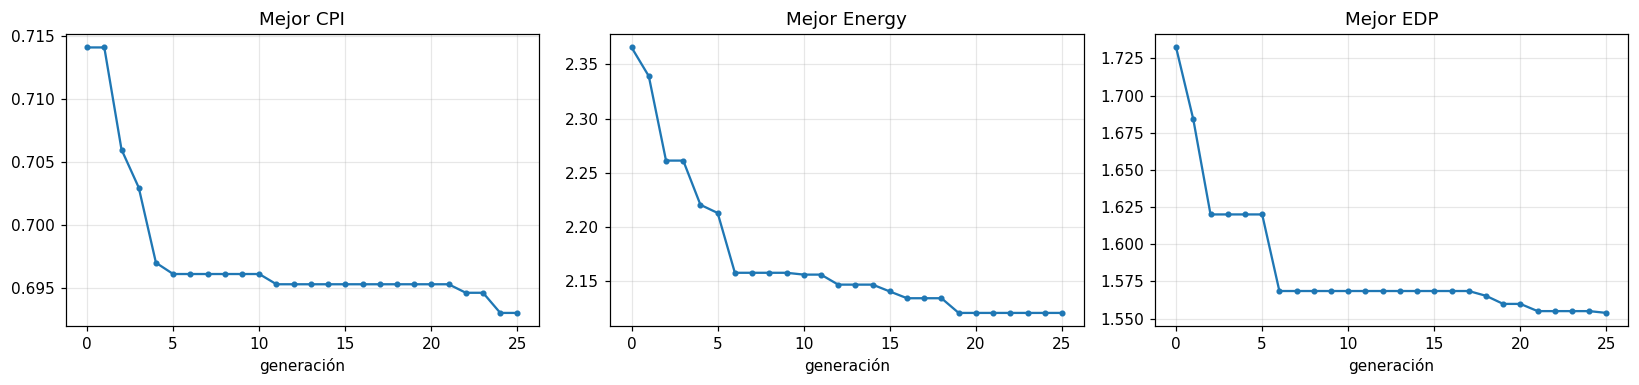

,gen,n_evals,pop_size,best_cpi,best_energy,best_edp
0,0,20,20,0.7141,2.3656,1.7324
5,5,138,24,0.6961,2.2130,1.6201
10,10,255,24,0.6961,2.1561,1.5686
15,15,374,24,0.6953,2.1406,1.5686
20,20,492,24,0.6953,2.1208,1.5599
25,25,611,24,0.6930,2.1208,1.5539


In [43]:
evo  = pd.read_csv(RESULTS_DIR / "exp3" / "evals_all.csv")
hist = pd.read_csv(RESULTS_DIR / "exp3" / "history.csv")
par  = pd.read_csv(RESULTS_DIR / "exp3" / "pareto.csv")
print(f"{len(evo)} evaluaciones válidas | generaciones 0 a {int(hist.gen.max())} | frente de Pareto: {len(par)} configuraciones")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (c, t) in zip(axs, [("best_cpi","Mejor CPI"),("best_energy","Mejor Energy"),("best_edp","Mejor EDP")]):
    ax.plot(hist.gen, hist[c], "o-", ms=3); ax.set_xlabel("generación"); ax.set_title(t)
plt.tight_layout(); plt.show()
hist.iloc[[0,5,10,15,20,25]].round(4)

**Convergencia.** Con solo 20 individuos válidos en la generación 0 (la por defecto y aleatorios) el mejor CPI ya era 0.714; tras 25 generaciones baja a 0.693. Energy pasa de 2.366 a 2.121 y el EDP de 1.732 a 1.554. Las mejoras se concentran en las primeras 10 generaciones y después el avance es lento, señal de convergencia hacia el frente de Pareto.

In [17]:
cols = ["l1i_size","l1d_size","l2_size","l1i_assoc","l1d_assoc","l2_assoc","front_width","issue_width","commit_width",
        "iq_entries","rob_entries","lq_entries","sq_entries","btb_entries","cpi","power_W","energy","edp"]
par.sort_values("cpi")[cols].round(4)

,l1i_size,l1d_size,l2_size,l1i_assoc,l1d_assoc,l2_assoc,front_width,issue_width,commit_width,iq_entries,rob_entries,lq_entries,sq_entries,btb_entries,cpi,power_W,energy,edp
0,64kB,32kB,256kB,4,2,16,8,8,8,64,192,68,72,8192,0.6930,3.4361,2.3813,1.6502
1,64kB,32kB,128kB,4,2,4,6,6,8,64,192,96,96,8192,0.6987,3.2619,2.2791,1.5925
2,64kB,32kB,128kB,4,2,4,6,6,8,64,192,48,72,8192,0.7044,3.2268,2.2729,1.6010
3,64kB,32kB,128kB,8,2,4,6,6,8,64,128,96,96,8192,0.7069,3.2035,2.2647,1.6010
4,64kB,32kB,128kB,4,2,16,6,6,8,64,128,68,96,8192,0.7071,3.1238,2.2088,1.5619
5,64kB,32kB,128kB,4,2,4,6,6,8,64,128,48,96,8192,0.7071,3.1199,2.2061,1.5599
6,64kB,32kB,128kB,4,2,4,6,6,8,64,128,48,32,8192,0.7091,3.0899,2.1912,1.5539
7,64kB,32kB,128kB,4,2,4,6,6,8,48,128,48,32,8192,0.7111,3.0757,2.1870,1.5551
8,64kB,32kB,128kB,2,2,8,6,6,6,48,128,48,32,4096,0.7250,3.0036,2.1777,1.5790
9,64kB,32kB,128kB,4,2,4,4,6,8,64,128,48,72,8192,0.7434,2.9080,2.1619,1.6072


## 5. Experimento 4 — McPAT, energía y EDP
Para cada simulación se convierte `stats.txt` + `config.json` a `config.xml` (script `gem5toMcPAT_cortexA76.py` sobre la plantilla `ARM_A76_2.1GHz.xml`), se ejecuta McPAT y se toma `Total Leakage` y `Runtime Dynamic` del bloque *Processor*. La fuerza bruta se simuló antes de integrar McPAT, por eso `edp_exp4.py` reprocesa los `stats.txt` ya existentes de las 1024 simulaciones; en NSGA‑II, en cambio, McPAT forma parte de cada evaluación.

In [ ]:
%%writefile scripts/edp_exp4.py
#!/usr/bin/env python3
"""
Experimento 4: McPAT + Energy + EDP sobre las simulaciones del DSE (exp. 2).

Para cada carpeta sims/<id>/ con result.json valido:
  1. Lee el CPI.
  2. Convierte stats.txt + config.json -> config.xml (gem5toMcPAT_cortexA76.py).
  3. Ejecuta McPAT y extrae Total Leakage y Runtime Dynamic del bloque Processor.
  4. Power  = Leakage + Runtime Dynamic
     Energy = Power  * CPI
     EDP    = Energy * CPI          (formulas de la guia)

Todo se guarda en exp4_EDP/ (al lado de build/, scripts/, sims/...):
  exp4_EDP/mcpat/<id>/{config.xml, mcpat_out.txt, mcpat_result.json}
  exp4_EDP/results_exp4.csv              (incremental)
  exp4_EDP/results_exp4_sorted_EDP.csv   (final, mejores primero)
  exp4_EDP/summary.txt                   (top 3 por CPI, energia y EDP + tiempos)

Reanudable: si existe mcpat_result.json para una simulacion, se salta.

Ejecutar desde la raiz de gem5:
    python3 edp_exp4.py --workers 4
    python3 edp_exp4.py --limit 2        # prueba rapida
"""

import argparse
import csv
import json
import os
import re
import shutil
import subprocess
import sys
import time
from concurrent.futures import ProcessPoolExecutor, as_completed

ROOT = os.getcwd()
SIMS_DIR = os.path.join(ROOT, "sims")
MCPAT_BIN = os.path.join(ROOT, "mcpat/mcpat")
CONVERTER = os.path.join(ROOT, "scripts/McPAT/gem5toMcPAT_cortexA76.py")
TEMPLATE = os.path.join(ROOT, "scripts/McPAT/ARM_A76_2.1GHz.xml")

OUT_DIR = os.path.join(ROOT, "exp4_EDP")
MCPAT_DIR = os.path.join(OUT_DIR, "mcpat")
CSV_PATH = os.path.join(OUT_DIR, "results_exp4.csv")
CSV_SORTED = os.path.join(OUT_DIR, "results_exp4_sorted_EDP.csv")
SUMMARY = os.path.join(OUT_DIR, "summary.txt")

PARAMS = ["l1d_size", "l2_size", "num_fu_intALU", "iq_entries", "rob_entries"]

RE_LEAK = re.compile(r"^\s*Total Leakage\s*=\s*([-+0-9.eE]+)\s*W")
RE_DYN = re.compile(r"^\s*Runtime Dynamic\s*=\s*([-+0-9.eE]+)\s*W")


def parse_mcpat(path):
    """Toma la PRIMERA aparicion de Total Leakage y Runtime Dynamic
    despues de la linea 'Processor:' (valores del procesador completo)."""
    leak = dyn = None
    in_proc = False
    with open(path) as f:
        for line in f:
            if line.strip() == "Processor:":
                in_proc = True
                continue
            if not in_proc:
                continue
            if leak is None:
                m = RE_LEAK.match(line)
                if m:
                    leak = float(m.group(1))
            if dyn is None:
                m = RE_DYN.match(line)
                if m:
                    dyn = float(m.group(1))
            if leak is not None and dyn is not None:
                break
    return leak, dyn


def process(sid):
    """Corre conversor + McPAT para una simulacion. Devuelve un dict."""
    simdir = os.path.join(SIMS_DIR, sid)
    outdir = os.path.join(MCPAT_DIR, sid)
    res_path = os.path.join(outdir, "mcpat_result.json")

    with open(os.path.join(simdir, "result.json")) as f:
        sim = json.load(f)

    # Reanudable
    if os.path.exists(res_path):
        with open(res_path) as f:
            return json.load(f)

    if os.path.isdir(outdir):
        shutil.rmtree(outdir)
    os.makedirs(outdir)

    stats = os.path.join(simdir, "stats.txt")
    cfgjson = os.path.join(simdir, "config.json")
    if not (os.path.exists(stats) and os.path.exists(cfgjson)):
        print(f"[ERROR] {sid}: faltan stats.txt o config.json", flush=True)
        return {"id": sid, "ok": False}

    # El conversor escribe config.xml en el directorio actual -> cwd=outdir
    t0 = time.time()
    conv = subprocess.run(
        [sys.executable, CONVERTER, stats, cfgjson, TEMPLATE],
        cwd=outdir, capture_output=True, text=True)
    t_conv = time.time() - t0
    xml = os.path.join(outdir, "config.xml")
    if conv.returncode != 0 or not os.path.exists(xml):
        print(f"[ERROR] {sid}: conversor fallo\n{conv.stderr[-500:]}", flush=True)
        return {"id": sid, "ok": False}

    t0 = time.time()
    out_txt = os.path.join(outdir, "mcpat_out.txt")
    with open(out_txt, "w") as out:
        rc = subprocess.run([MCPAT_BIN, "-infile", xml, "-print_level", "1"],
                            cwd=outdir, stdout=out, stderr=subprocess.STDOUT).returncode
    t_mcpat = time.time() - t0

    leak, dyn = parse_mcpat(out_txt)
    if rc != 0 or leak is None or dyn is None:
        print(f"[ERROR] {sid}: McPAT rc={rc}, leak={leak}, dyn={dyn}", flush=True)
        return {"id": sid, "ok": False}

    cpi = sim["cpi"]
    power = leak + dyn
    energy = power * cpi          # formula de la guia
    edp = energy * cpi            # formula de la guia
    res = {
        "id": sid,
        **{k: sim[k] for k in PARAMS},
        "ok": True,
        "cpi": cpi,
        "simSeconds": sim["simSeconds"],
        "hostSeconds": sim["hostSeconds"],
        "leakage_W": leak,
        "dynamic_W": dyn,
        "power_W": power,
        "energy": energy,
        "edp": edp,
        # referencia: energia real en Joules (mismo ranking que con CPI)
        "energy_J": power * sim["simSeconds"],
        "converter_seconds": t_conv,
        "mcpat_seconds": t_mcpat,
    }
    with open(res_path, "w") as f:
        json.dump(res, f)
    print(f"[OK] {sid}  CPI={cpi:.4f}  P={power:.3f}W  EDP={edp:.4f}  "
          f"(mcpat {t_mcpat:.1f}s)", flush=True)
    return res


def write_csv(path, rows):
    if not rows:
        return
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)


def fmt(r):
    cfg = ", ".join(f"{k}={r[k]}" for k in PARAMS)
    return (f"{cfg}\n      CPI={r['cpi']:.4f}  Power={r['power_W']:.3f} W  "
            f"Energy={r['energy']:.4f}  EDP={r['edp']:.4f}")


def write_summary(rows, wall_total):
    lines = [f"Simulaciones procesadas: {len(rows)}", ""]
    for title, key in [("Mejor RENDIMIENTO (CPI minimo)", "cpi"),
                       ("Mejor ENERGIA (Energy minima)", "energy"),
                       ("Mejor EDP (EDP minimo)", "edp")]:
        lines.append(f"== Top 3 - {title} ==")
        for i, r in enumerate(sorted(rows, key=lambda r: r[key])[:3], 1):
            lines.append(f"  {i}. {fmt(r)}")
        lines.append("")

    pw = [r["power_W"] for r in rows]
    lines += [f"Rango de potencia: {min(pw):.3f} W - {max(pw):.3f} W", ""]

    t_m = [r["mcpat_seconds"] for r in rows]
    t_c = [r["converter_seconds"] for r in rows]
    t_g = [r["hostSeconds"] for r in rows]
    lines += [
        "== Velocidades ==",
        f"gem5  : {sum(t_g)/len(t_g):.1f} s por simulacion | total {sum(t_g)/3600:.2f} h (suma de hostSeconds)",
        f"McPAT : {sum(t_m)/len(t_m):.2f} s por simulacion | total {sum(t_m)/60:.2f} min (suma)",
        f"Conversor gem5->McPAT: {sum(t_c)/len(t_c):.2f} s por simulacion | total {sum(t_c)/60:.2f} min (suma)",
        f"Tiempo real de esta ejecucion del experimento 4: {wall_total/60:.2f} min",
    ]
    text = "\n".join(lines)
    with open(SUMMARY, "w") as f:
        f.write(text + "\n")
    print("\n" + text)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--workers", type=int, default=4)
    ap.add_argument("--limit", type=int, default=None,
                    help="maximo de simulaciones a procesar (pruebas)")
    args = ap.parse_args()

    for p in (SIMS_DIR, MCPAT_BIN, CONVERTER, TEMPLATE):
        if not os.path.exists(p):
            sys.exit(f"No se encontro '{p}'. Ejecuta desde la carpeta de gem5.")
    os.makedirs(MCPAT_DIR, exist_ok=True)

    # Solo simulaciones validas (result.json con ok=True)
    ids = []
    for sid in sorted(os.listdir(SIMS_DIR)):
        rp = os.path.join(SIMS_DIR, sid, "result.json")
        if os.path.exists(rp):
            with open(rp) as f:
                if json.load(f).get("ok"):
                    ids.append(sid)
    if args.limit:
        ids = ids[: args.limit]
    print(f"Simulaciones validas a procesar: {len(ids)} | workers: {args.workers}")

    rows = []
    failed = []
    t_start = time.time()
    with ProcessPoolExecutor(max_workers=args.workers) as ex:
        futs = {ex.submit(process, sid): sid for sid in ids}
        for fut in as_completed(futs):
            r = fut.result()
            if r.get("ok"):
                rows.append(r)
                write_csv(CSV_PATH, rows)   # incremental
            else:
                failed.append(futs[fut])
    wall = time.time() - t_start

    if not rows:
        sys.exit("No se proceso ninguna simulacion con exito.")

    rows.sort(key=lambda r: r["edp"])       # mejores primero
    write_csv(CSV_SORTED, rows)
    write_summary(rows, wall)

    if failed:
        print(f"\n[AVISO] {len(failed)} simulaciones fallaron: {failed[:5]}...")
    print(f"\nCSV ordenado: {CSV_SORTED}")


if __name__ == "__main__":
    main()

### 5.1 Comando de ejecución:

In [ ]:
run_script("edp_exp4.py", "--workers", "4")   

In [18]:
bf  = pd.read_csv(RESULTS_DIR / "exp4" / "results_exp4.csv"); bf = bf[bf.ok]
bf["metodo"] = "Fuerza bruta (5 par.)"; evo["metodo"] = "NSGA-II (14 par.)"
d_bf  = bf[(bf[P5] == pd.Series(DEF)).all(axis=1)].iloc[0]
print(f"Configuración por defecto: CPI={d_bf.cpi:.4f}  Power={d_bf.power_W:.3f} W  Energy={d_bf.energy:.4f}  EDP={d_bf.edp:.4f}")
print(f"Rango de potencia (fuerza bruta): {bf.power_W.min():.3f} – {bf.power_W.max():.3f} W")
print(f"Rango de potencia (NSGA-II):      {evo.power_W.min():.3f} – {evo.power_W.max():.3f} W")

Configuración por defecto: CPI=0.9061  Power=2.611 W  Energy=2.3656  EDP=2.1434
Rango de potencia (fuerza bruta): 2.491 – 3.267 W
Rango de potencia (NSGA-II):      2.144 – 3.917 W


### 5.2 Efecto de cada recurso sobre potencia, energía y EDP (fuerza bruta)

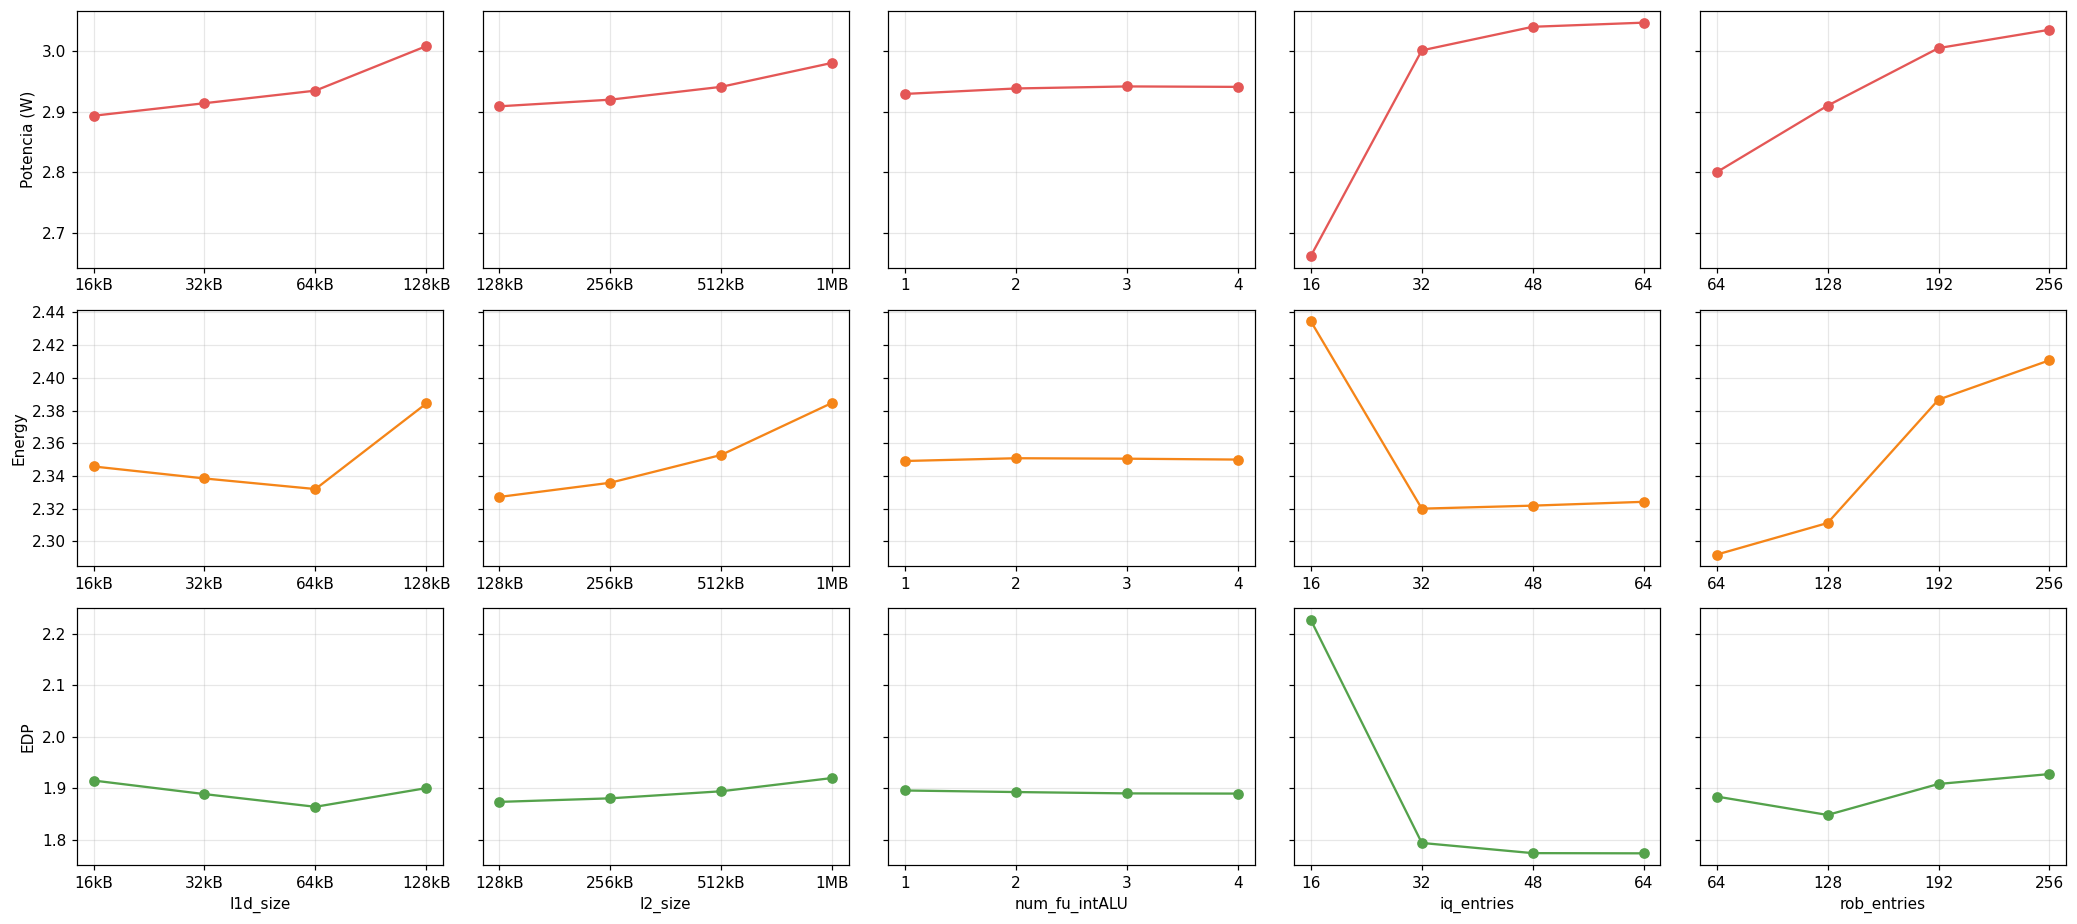

In [19]:
fig, axs = plt.subplots(3, 5, figsize=(19, 8.5), sharey="row")
for j, p in enumerate(P5):
    vals = sorted(bf[p].unique(), key=kb if p.endswith("size") else float)
    g = bf.groupby(p)[["power_W","energy","edp"]].mean().loc[vals]
    for i, (c, lab) in enumerate([("power_W","Potencia (W)"),("energy","Energy"),("edp","EDP")]):
        axs[i, j].plot(range(len(vals)), g[c], "o-", color=["#e45756","#f58518","#54a24b"][i])
        axs[i, j].set_xticks(range(len(vals))); axs[i, j].set_xticklabels([str(v) for v in vals])
        if i == 2: axs[i, j].set_xlabel(p)
        if j == 0: axs[i, j].set_ylabel(lab)
plt.tight_layout(); plt.show()

- **Potencia:** crece con casi todos los recursos: ROB (2.80 W con 64 → 3.04 W con 256), IQ (2.66 → 3.05 W), L1D (2.89 → 3.01 W) y L2 (2.91 → 2.98 W). El número de ALUs casi no la afecta (limitación de McPAT).
- **ROB > 128 y L2 > 128 kB** no mejoran el CPI pero sí suben la potencia, así que empeoran Energy y EDP: son recursos mal aprovechados para esta carga.
- **IQ:** pasar de 16 a 32 sube la potencia (2.66 → 3.00 W) pero baja tanto el CPI que Energy y EDP mejoran claramente (EDP medio 2.23 → 1.79).

### 5.3 Todos los puntos simulados: rendimiento frente a energía

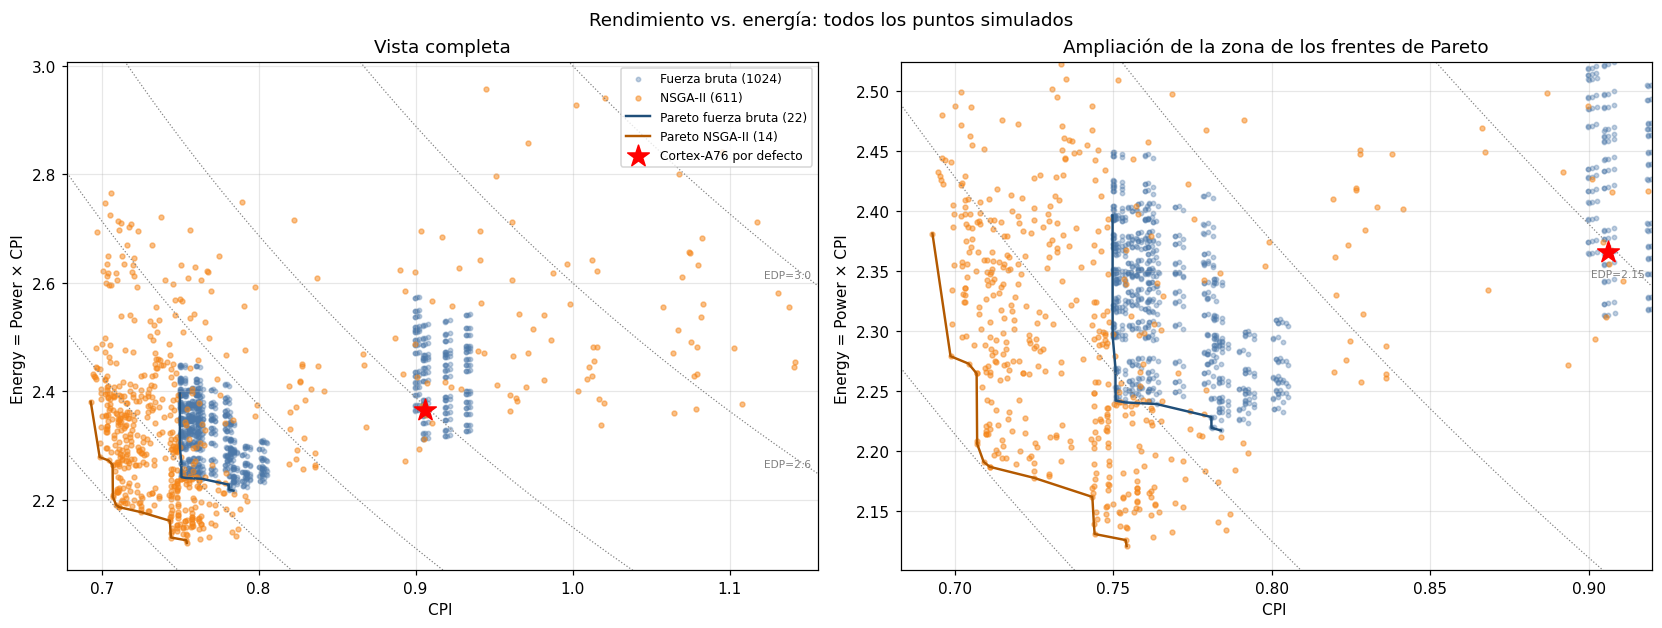

In [47]:
fronts = {"Pareto fuerza bruta": (pareto_front(bf), "#1f4e79"), "Pareto NSGA-II": (pareto_front(evo), "#b35900")}

def dibujar(ax, xlim, ylim, leyenda=False):
    ax.scatter(bf.cpi,  bf.energy,  s=8,  alpha=0.35, c="#4c78a8", label=f"Fuerza bruta ({len(bf)})")
    ax.scatter(evo.cpi, evo.energy, s=10, alpha=0.5,  c="#f58518", label=f"NSGA-II ({len(evo)})")
    for lab, (f, c) in fronts.items():
        ax.plot(f.cpi, f.energy, "-", c=c, lw=1.6, label=f"{lab} ({len(f)})")
    ax.scatter([d_bf.cpi], [d_bf.energy], marker="*", s=220, c="red", zorder=5, label="Cortex-A76 por defecto")
    # Isolíneas de EDP (Energy = k / CPI); la etiqueta va donde la curva cruza el borde del eje y solo si es visible
    xs = np.linspace(*xlim, 200)
    for k in (1.55, 1.7, 1.9, 2.15, 2.6, 3.0):
        ax.plot(xs, k / xs, ":", c="gray", lw=0.8)
        for xl in (xlim[1] - 0.01 * (xlim[1] - xlim[0]), ):
            yl = k / xl
            if ylim[0] < yl < ylim[1]:
                ax.text(xl, yl, f"EDP={k}", fontsize=7, color="gray", ha="right", va="bottom", clip_on=True)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)          # los límites se fijan al final: las isolíneas no los amplían
    ax.set_xlabel("CPI "); ax.set_ylabel("Energy = Power × CPI ")
    if leyenda: ax.legend(loc="upper right", fontsize=8)

allp = pd.concat([bf, evo], ignore_index=True)
m = 0.03
full_x = (allp.cpi.min() - m * 0.5, allp.cpi.max() + m * 0.5)
full_y = (allp.energy.min() - 0.05, allp.energy.max() + 0.05)
# Zoom: región donde están los frentes de Pareto y la mayor densidad de puntos
zoom_x = (allp.cpi.min() - 0.01, allp.cpi.quantile(0.80) + 0.02)
zoom_y = (allp.energy.min() - 0.02, allp.energy.quantile(0.90) + 0.03)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True)
dibujar(axs[0], full_x, full_y, leyenda=True); axs[0].set_title("Vista completa")
dibujar(axs[1], zoom_x, zoom_y);                axs[1].set_title("Ampliación de la zona de los frentes de Pareto")
fig.suptitle("Rendimiento vs. energía: todos los puntos simulados")
plt.show()

Las curvas punteadas de EDP cuanto más cerca del origen significa que tuvieron un mejor resultado. Se observa que:
- Los puntos de **NSGA‑II** alcanzan CPI más bajos (hasta 0.693) y desplazan el frente de Pareto hacia abajo‑izquierda respecto a la fuerza bruta, que no puede bajar de 0.750 por tener fijos los demás parámetros (anchos, LSQ, BTB…).
- La configuración por defecto (estrella) está muy lejos del frente: se puede ganar rendimiento y energía a la vez.
- NSGA‑II también visita muchos puntos malos (CPI hasta 1.14, p. ej. anchos de 2).

### 5.3 Las tres mejores configuraciones: rendimiento, energía y EDP

In [21]:
allp = pd.concat([bf, evo], ignore_index=True)
rows = []
for crit, lab in [("cpi","Mejor rendimiento (CPI mínimo)"), ("energy","Mejor energía (Energy mínima)"), ("edp","Mejor EDP")]:
    r = allp.loc[allp[crit].idxmin()]
    rows.append({"criterio": lab, "método": r.metodo, "CPI": r.cpi, "Power (W)": r.power_W, "Energy": r.energy, "EDP": r.edp})
best = pd.DataFrame(rows).set_index("criterio")
best.loc["Cortex-A76 por defecto"] = ["—", d_bf.cpi, d_bf.power_W, d_bf.energy, d_bf.edp]
display(best.round(4))
for crit in ("cpi", "energy", "edp"):
    r = evo.loc[evo[crit].idxmin()]
    print(f"\n[{crit.upper()}] configuración NSGA-II:")
    print("   ", ", ".join(f"{k}={r[k]}" for k in ["l1i_size","l1d_size","l2_size","l1i_assoc","l1d_assoc","l2_assoc","front_width","issue_width","commit_width","iq_entries","rob_entries","lq_entries","sq_entries","btb_entries"]))

,método,CPI,Power (W),Energy,EDP
criterio,,,,,
Mejor rendimiento (CPI mínimo),NSGA-II (14 par.),0.6930,3.4361,2.3813,1.6502
Mejor energía (Energy mínima),NSGA-II (14 par.),0.7542,2.8119,2.1208,1.5996
Mejor EDP,NSGA-II (14 par.),0.7091,3.0899,2.1912,1.5539
Cortex-A76 por defecto,—,0.9061,2.6109,2.3656,2.1434



[CPI] configuración NSGA-II:
    l1i_size=64kB, l1d_size=32kB, l2_size=256kB, l1i_assoc=4, l1d_assoc=2, l2_assoc=16, front_width=8, issue_width=8, commit_width=8, iq_entries=64, rob_entries=192, lq_entries=68, sq_entries=72, btb_entries=8192

[ENERGY] configuración NSGA-II:
    l1i_size=64kB, l1d_size=32kB, l2_size=128kB, l1i_assoc=2, l1d_assoc=2, l2_assoc=8, front_width=4, issue_width=4, commit_width=8, iq_entries=48, rob_entries=128, lq_entries=48, sq_entries=32, btb_entries=8192

[EDP] configuración NSGA-II:
    l1i_size=64kB, l1d_size=32kB, l2_size=128kB, l1i_assoc=4, l1d_assoc=2, l2_assoc=4, front_width=6, issue_width=6, commit_width=8, iq_entries=64, rob_entries=128, lq_entries=48, sq_entries=32, btb_entries=8192


**Configuraciones óptimas globales** (todas halladas por NSGA‑II; detalle del genoma en la salida anterior y en `summary.txt` de `results/exp3/`):

| Criterio | CPI | Power | Energy | EDP | Rasgos de la configuración |
|---|---|---|---|---|---|
| **Rendimiento** | **0.6930** | 3.436 W | 2.381 | 1.650 | Anchos 8/8/8, IQ 64, ROB 192, BTB 8192, L1D 32 kB (2 vías), L2 256 kB de 16 vías |
| **Energía** | 0.7542 | **2.812 W** | **2.121** | 1.600 | Anchos 4/4/8, IQ 48, ROB 128, LQ 48/SQ 32, BTB 8192, L1D 32 kB, L2 128 kB |
| **EDP** | 0.7091 | 3.090 W | 2.191 | **1.554** | Anchos 6/6/8, IQ 64, ROB 128, LQ 48/SQ 32, BTB 8192, L1D 32 kB, L2 128 kB |
| Cortex‑A76 por defecto | 0.9061 | 2.611 W | 2.366 | 2.143 | — |

El mejor EDP (1.554) mejora un **27.5 %** al del Cortex‑A76 por defecto (2.143) y un 7.7 % al mejor de la fuerza bruta (1.683). El mejor CPI (0.693) es un 23.5 % menor que el de la configuración base.

**Patrones comunes en las mejores configuraciones:** `commit_width = 8`, `btb_entries = 8192`, L1D pequeña (32 kB, 2 vías) y L2 pequeña (128–256 kB). Para eficiencia energética conviene un ancho intermedio (6) y colas de carga/almacenamiento reducidas; el ancho 8 solo compensa si se busca rendimiento puro.

NSGA‑II explora un espacio mucho mayor (14 genes frente a 5) y, por tanto, su ventaja sobre la fuerza bruta no se debe solo al algoritmo sino también a que puede modificar parámetros (anchos, BTB, colas, asociatividad) que la fuerza bruta mantuvo fijos. Lo que sí demuestra es que, con 611 evaluaciones (menos que las 1024 de la fuerza bruta), encuentra mejores compromisos en un espacio gigantesco.

## 6. Velocidad de simulación

In [50]:
x2 = pd.read_csv(RESULTS_DIR / "exp2" / "results_exp2.csv"); x2 = x2[x2.ok]
INSTS = 230472873
rows = []
# gem5 en aislamiento (Exp. 1, simulaciones secuenciales)
h = e1.hostSeconds.mean()
rows.append(["gem5 – 1 simulación aislada (Exp. 1, media de 3)", f"{h:.0f} s", f"{INSTS/h/1e3:.0f} KIPS"])
# gem5 en la fuerza bruta (5 en paralelo)
rows.append(["gem5 – 1 simulación (fuerza bruta, 5 en paralelo)", f"{x2.wall_s.mean():.0f} s", f"{INSTS/x2.wall_s.mean()/1e3:.0f} KIPS"])
rows.append(["gem5 – fuerza bruta completa (1024 sims)", f"suma {x2.wall_s.sum()/3600:.1f} h CPU; ≈ {x2.wall_s.sum()/5/3600:.1f} h reales (estimado, 5 workers)", ""])
rows.append(["gem5 – NSGA-II (611 sims, 6 workers)", f"suma {evo.gem5_wall_s.sum()/3600:.1f} h CPU; ≈ {evo.wall_total_s.sum()/6/3600:.1f} h reales ", f"{evo.gem5_wall_s.mean():.0f} s/sim"])
rows.append(["McPAT – 1 simulación (fuerza bruta)", f"{bf.mcpat_seconds.mean():.1f} s", ""])
rows.append(["McPAT – 1024 simulaciones", f"{bf.mcpat_seconds.sum()/60:.0f} min de suma (97 min reales con 4 workers)", ""])
rows.append(["McPAT – 1 simulación (NSGA-II)", f"{evo.mcpat_seconds.mean():.1f} s", ""])
rows.append(["Conversor gem5→McPAT", f"{bf.converter_seconds.mean():.2f} s/sim", ""])
pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows, columns=["Concepto", "Tiempo", "Velocidad"])

,Concepto,Tiempo,Velocidad
0,"gem5 – 1 simulación aislada (Exp. 1, media de 3)",561 s,411 KIPS
1,"gem5 – 1 simulación (fuerza bruta, 5 en paralelo)",688 s,335 KIPS
2,gem5 – fuerza bruta completa (1024 sims),"suma 195.6 h CPU; ≈ 39.1 h reales (estimado, 5 workers)",
3,"gem5 – NSGA-II (611 sims, 6 workers)",suma 129.7 h CPU; ≈ 22.7 h reales,764 s/sim
4,McPAT – 1 simulación (fuerza bruta),41.3 s,
5,McPAT – 1024 simulaciones,705 min de suma (97 min reales con 4 workers),
6,McPAT – 1 simulación (NSGA-II),37.5 s,
7,Conversor gem5→McPAT,0.18 s/sim,


- **gem5** simula ≈230 M de instrucciones en ≈9–13 minutos (≈0.3–0.4 MIPS), miles de veces más lento que el hardware real, como es habitual en un simulador detallado *out‑of‑order*.
- **McPAT** es unas 15 veces más rápido que gem5 (≈40 s por configuración), por lo que el coste de la energía es pequeño frente al de la simulación.
- Los tiempos reales totales de la fuerza bruta y de NSGA‑II son **estimaciones** (suma de tiempos ÷ número de workers), no tiempos medidos: ambos se ejecutaron por tandas.

## 7. Conclusiones y aprendizajes

**1. Rendimiento y energía como objetivos de diseño.** La práctica permitió aplicar los conceptos de rendimiento (CPI) y consumo de potencia al tratarlos como objetivos concretos a mejorar. Esto obligó a analizar las decisiones de la microarquitectura por su efecto en ambas métricas a la vez.

**2. Identificación de cuellos de botella.** Las simulaciones mostraron que algunos parámetros limitan el rendimiento de forma desproporcionada. En el Experimento 1, ensanchar el pipeline y duplicar las cachés L1 apenas mejoró el CPI, mientras que en la exploración completa la cola de instrucciones (`iq_entries`) de 16 a 32 entradas redujo el CPI medio en un 15.5 %. Un solo recurso mal dimensionado puede anular el beneficio de los demás, por lo que conviene localizar el cuello de botella antes de aumentar recursos.

**3. Equilibrio entre rendimiento y consumo.** Varios parámetros influyen en el rendimiento pero también aumentan la potencia, de modo que mejorar uno de los dos objetivos puede empeorar el otro. 

**4. Alcance del espacio de diseño y algoritmo evolutivo.** El espacio de 14 parámetros del NSGA-II tiene del orden de 10⁸ combinaciones, imposibles de simular por completo. Con solo 26 generaciones (611 evaluaciones) el algoritmo encontró mejores compromisos que la fuerza bruta de 1024 simulaciones, aunque esa comparación está condicionada porque explora más parámetros. También permitió apreciar cuántos elementos intervienen en el comportamiento final de un procesador y la limitación temporal que se tiene para simular todas las combinaciones.

**5. Automatización y paralelismo.** Automatizar las simulaciones con scripts y ejecutar varias a la vez (5 en la fuerza bruta y 6 en NSGA-II, aprovechando los 6 núcleos / 12 hilos de la máquina) redujo de forma importante el tiempo total, ya que cada simulación de gem5 usa un solo hilo y dura unos 10 a 13 minutos. Esto sirvió como introducción práctica a la computación paralela.

